In [ ]:
cd /home/lihaoxing/jupyter

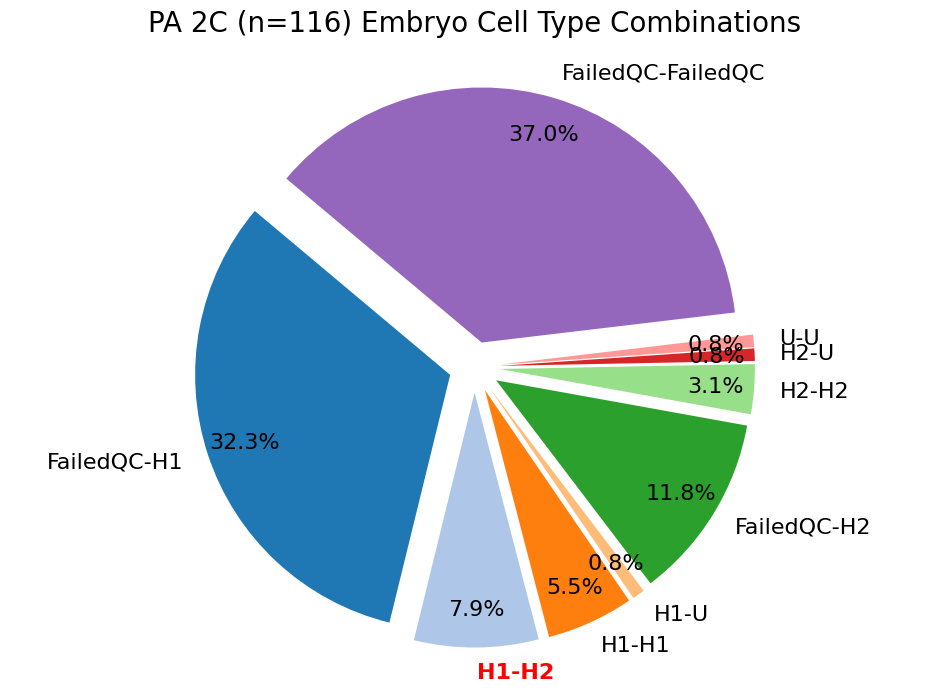

In [4]:
#hic
#PA 2C 包括不完整的
from collections import defaultdict, Counter
import matplotlib.pyplot as plt

# 假设文件名为 "PA-2C-blastomere-type.txt"
input_file_name = "PA-2C-blastomere-type.txt"
output_file_name = "PA-2C-embryo_type_combinations.txt"

# 读取文件并解析数据
def read_and_parse(input_file_name):
    with open(input_file_name, 'r') as file:
        lines = file.readlines()
    
    # 初始化一个字典来存储每个胚胎的细胞类型
    embryo_data = defaultdict(list)
    
    for line in lines:
        parts = line.strip().split('\t')
        if len(parts) < 2:
            continue
        embryo_id = parts[0].split('-')[:2]
        cell_type = parts[1].split('-')[2]
        # 将胚胎ID转换为字符串作为字典的键
        embryo_id_str = '-'.join(embryo_id)
        embryo_data[embryo_id_str].append(cell_type)
    
    return embryo_data

# 统计胚胎的细胞类型组合
def count_combination(embryo_data):
    embryo_type_count = Counter()
    embryo_sum = len(embryo_data)
    
    for cell_types in embryo_data.values():
        if len(cell_types) == 1:
            # 如果只有一个细胞类型，添加FailedQC作为第二个细胞类型
            cell_types.append('FailedQC')
        # 将细胞类型排序，并去除重复，以便A1-A2和A2-A1被视为同一组合
        sorted_types = sorted(set(cell_types))
        # 如果只有一个类型，也将其视为一个组合
        if len(sorted_types) == 1:
            combination = f"{sorted_types[0]}-{sorted_types[0]}"
        else:
            combination = '-'.join(sorted_types)
        embryo_type_count[combination] += 1
    
    return embryo_data, embryo_type_count, embryo_sum

# 计算百分比并写入文件
def calculate_percentages_and_write(embryo_data, combination_counts, total_embryos, output_file_name):
    with open(output_file_name, 'w') as output_file:
        # 写入胚胎ID和对应的类型组合
        for embryo_id, cell_types in embryo_data.items():
            if len(cell_types) == 1:
                # 如果只有一个细胞类型，添加FailedQC作为第二个细胞类型
                cell_types.append('FailedQC')
            sorted_types = sorted(set(cell_types))
            if len(sorted_types) == 1:
                combination = f"{sorted_types[0]}-{sorted_types[0]}"
            else:
                combination = '-'.join(sorted_types)
            output_file.write(f"Embryo ID: {embryo_id}, Cell Types: {combination}\n")
        
        # 写入每种组合的数量和百分比
        output_file.write("\nType Combinations and Percentages:\n")
        for combination, count in combination_counts.items():
            percentage = (count / total_embryos) * 100
            output_file.write(f"{combination}: {count} ({percentage:.2f}%)\n")
    
    return combination_counts

# 绘制饼图
def plot_pie_chart(combination_counts):
    labels = list(combination_counts.keys())
    sizes = combination_counts.values()
    cmap = plt.get_cmap('tab20')  # 获取tab20颜色映射对象
    colors = [cmap(i) for i in range(len(labels))]  # 生成颜色列表

    plt.figure(figsize=(12, 8))  # 增加图形大小
    explode = [0.1] * len(labels)  # 稍微分离每个部分
    wedges, texts, autotexts = plt.pie(sizes, labels=labels, autopct='%1.1f%%', startangle=140, 
                                        colors=colors, textprops={'fontsize': 16}, explode=explode, 
                                        pctdistance=0.85, labeldistance=1.1)

    # 设置特定标签的颜色和加粗
    for i, text in enumerate(texts):
        if labels[i] == "H1-H2":
            text.set_color('red')
            text.set_fontweight('bold')

    plt.axis('equal')  # 使饼图为圆形
    plt.title('PA 2C (n=116) Embryo Cell Type Combinations', fontsize=20, pad=20)
    plt.show()

# 主函数
def main():
    embryo_data = read_and_parse(input_file_name)
    embryo_data, combination_counts, total_embryos = count_combination(embryo_data)
    combination_counts = calculate_percentages_and_write(embryo_data, combination_counts, total_embryos, output_file_name)
    plot_pie_chart(combination_counts)

if __name__ == "__main__":
    main()

Number of complete embryos: 24

[RED EMBRYOS: H1-H2]

2-105
2-106
2-113
2-17
2-40
2-46
2-72
2-83
NPB-41
NPB-5

Total H1-H2 embryos: 10
Results saved to: PA-2C-embryo_type_combinations_complete_only.txt


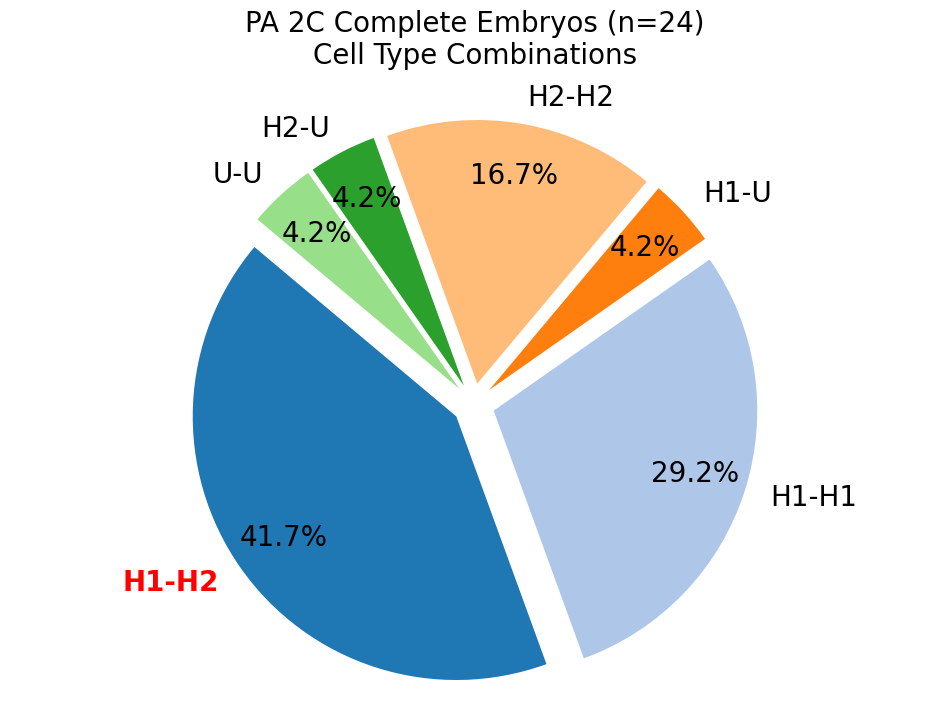

In [1]:
# PA 2C blastomere type analysis — only complete embryos
#hic
from collections import defaultdict, Counter
import matplotlib.pyplot as plt
from IPython.display import SVG, display

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

# 输入输出文件
input_file_name = "PA-2C-blastomere-type.txt"
output_file_name = "PA-2C-embryo_type_combinations_complete_only.txt"


# =========================
# 1. 读取并解析数据
# =========================
def read_and_parse(input_file_name):

    embryo_data = defaultdict(list)

    with open(input_file_name, 'r') as file:
        for line in file:
            parts = line.strip().split('\t')
            if len(parts) < 2:
                continue

            # 胚胎ID：取前两段
            embryo_id = parts[0].split('-')[:2]
            embryo_id_str = '-'.join(embryo_id)

            # 细胞类型：第3段
            cell_type = parts[1].split('-')[2]

            embryo_data[embryo_id_str].append(cell_type)

    return embryo_data


# =========================
# 2. 只保留完整胚胎并统计组合
# =========================
def count_complete_embryos(embryo_data):

    embryo_type_count = Counter()
    filtered_embryos = {}

    # ⭐ 新增：组合 -> embryo
    combination_to_embryos = defaultdict(list)

    for embryo_id, cell_types in embryo_data.items():

        if len(cell_types) != 2:
            continue

        if "FailedQC" in cell_types:
            continue

        filtered_embryos[embryo_id] = cell_types

        sorted_types = sorted(cell_types)

        if sorted_types[0] == sorted_types[1]:
            combination = f"{sorted_types[0]}-{sorted_types[0]}"
        else:
            combination = '-'.join(sorted_types)

        embryo_type_count[combination] += 1

        # ⭐ 记录
        combination_to_embryos[combination].append(embryo_id)

    total_embryos = len(filtered_embryos)

    return filtered_embryos, embryo_type_count, total_embryos, combination_to_embryos


# =========================
# 3. 写入结果文件
# =========================
def write_results(embryo_data, combination_counts, total_embryos, output_file_name):

    with open(output_file_name, 'w') as output_file:

        output_file.write("Complete embryos only (2 blastomeres, both passed QC)\n\n")

        # 每个胚胎的组合
        for embryo_id, cell_types in embryo_data.items():

            sorted_types = sorted(cell_types)

            if sorted_types[0] == sorted_types[1]:
                combination = f"{sorted_types[0]}-{sorted_types[0]}"
            else:
                combination = '-'.join(sorted_types)

            output_file.write(f"{embryo_id}\t{combination}\n")

        # 统计结果
        output_file.write("\nType Combinations and Percentages:\n")

        for combination, count in combination_counts.items():
            percentage = (count / total_embryos) * 100
            output_file.write(f"{combination}: {count} ({percentage:.2f}%)\n")

    print("Results saved to:", output_file_name)


# =========================
# 4. 绘制饼图
# =========================
def plot_pie_chart(combination_counts, total_embryos):

    labels = list(combination_counts.keys())
    sizes = list(combination_counts.values())

    cmap = plt.get_cmap('tab20')
    colors = [cmap(i) for i in range(len(labels))]

    plt.figure(figsize=(12, 8))

    explode = [0.08] * len(labels)

    wedges, texts, autotexts = plt.pie(
        sizes,
        labels=labels,
        autopct='%1.1f%%',
        startangle=140,
        colors=colors,
        explode=explode,
        textprops={'fontsize': 20},
        pctdistance=0.8,
        labeldistance=1.1
    )

    # 强调 H1-H2（如果存在）
    for i, text in enumerate(texts):
        if labels[i] == "H1-H2":
            text.set_color('red')
            text.set_fontweight('bold')

    plt.axis('equal')

    plt.title(
        f'PA 2C Complete Embryos (n={total_embryos})\nCell Type Combinations',
        fontsize=20,
        pad=20
    )
    plt.savefig('PA_2C_embryo_type_count.svg', dpi=300, bbox_inches='tight', transparent=True)
    plt.show()


# =========================
# 5. 主程序
# =========================
def main():

    embryo_data = read_and_parse(input_file_name)

    filtered_embryos, combination_counts, total_embryos, combo_to_embryos = \
        count_complete_embryos(embryo_data)

    print("Number of complete embryos:", total_embryos)

    # =========================
    # 🔴 打印 H1-H2 胚胎
    # =========================
    target = "H1-H2"

    print("\n[RED EMBRYOS: H1-H2]\n")

    if target in combo_to_embryos:

        for eid in combo_to_embryos[target]:
            print(eid)

        print(f"\nTotal H1-H2 embryos: {len(combo_to_embryos[target])}")

    else:
        print("No H1-H2 embryos found")

    # =========================
    # 正常流程
    # =========================
    write_results(
        filtered_embryos,
        combination_counts,
        total_embryos,
        output_file_name
    )

    plot_pie_chart(combination_counts, total_embryos)

if __name__ == "__main__":
    main()

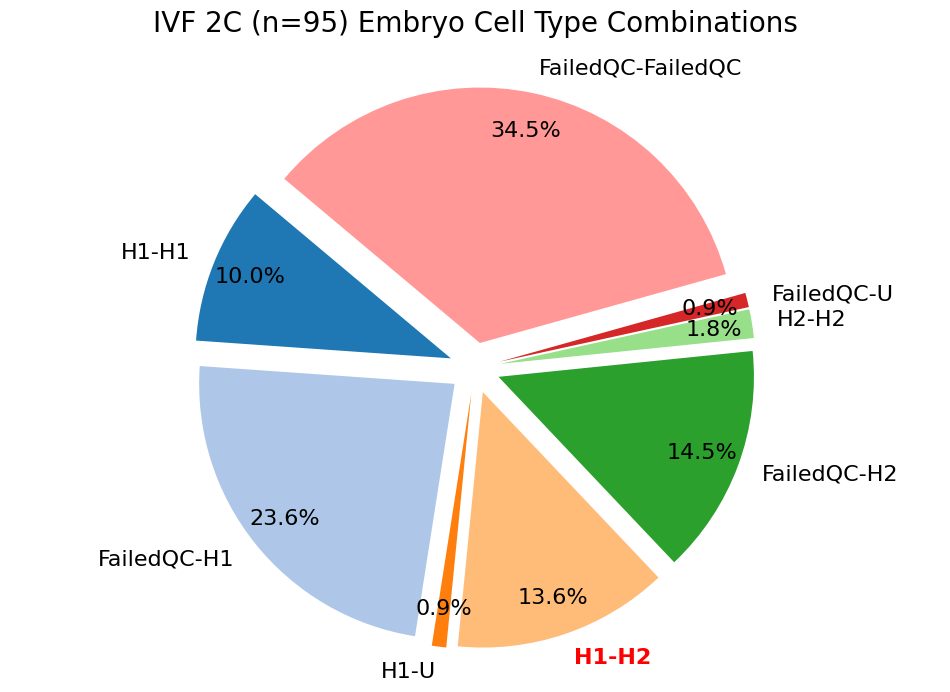

In [1]:
#hic
#IVF 2C
from collections import defaultdict, Counter
import matplotlib.pyplot as plt

input_file_name = "IVF-2C-blastomere-type.txt"
output_file_name = "IVF-2C-embryo_type_combinations.txt"

# 读取文件并解析数据
def read_and_parse(input_file_name):
    with open(input_file_name, 'r') as file:
        lines = file.readlines()
    
    # 初始化一个字典来存储每个胚胎的细胞类型
    embryo_data = defaultdict(list)
    
    for line in lines:
        parts = line.strip().split('\t')
        if len(parts) < 2:
            continue
        embryo_id = parts[0].split('-')[:3]
        cell_type = parts[1].split('-')[2]
        # 将胚胎ID转换为字符串作为字典的键
        embryo_id_str = '-'.join(embryo_id)
        embryo_data[embryo_id_str].append(cell_type)
    
    return embryo_data

# 统计胚胎的细胞类型组合
def count_combination(embryo_data):
    embryo_type_count = Counter()
    embryo_sum = len(embryo_data)
    
    for cell_types in embryo_data.values():
        if len(cell_types) == 1:
            # 如果只有一个细胞类型，添加FailedQC作为第二个细胞类型
            cell_types.append('FailedQC')
        # 将细胞类型排序，并去除重复，以便A1-A2和A2-A1被视为同一组合
        sorted_types = sorted(set(cell_types))
        # 如果只有一个类型，也将其视为一个组合
        if len(sorted_types) == 1:
            combination = f"{sorted_types[0]}-{sorted_types[0]}"
        else:
            combination = '-'.join(sorted_types)
        embryo_type_count[combination] += 1
    
    return embryo_data, embryo_type_count, embryo_sum

# 计算百分比并写入文件
def calculate_percentages_and_write(embryo_data, combination_counts, total_embryos, output_file_name):
    with open(output_file_name, 'w') as output_file:
        # 写入胚胎ID和对应的类型组合
        for embryo_id, cell_types in embryo_data.items():
            if len(cell_types) == 1:
                # 如果只有一个细胞类型，添加FailedQC作为第二个细胞类型
                cell_types.append('FailedQC')
            sorted_types = sorted(set(cell_types))
            if len(sorted_types) == 1:
                combination = f"{sorted_types[0]}-{sorted_types[0]}"
            else:
                combination = '-'.join(sorted_types)
            output_file.write(f"Embryo ID: {embryo_id}, Cell Types: {combination}\n")
        
        # 写入每种组合的数量和百分比
        output_file.write("\nType Combinations and Percentages:\n")
        for combination, count in combination_counts.items():
            percentage = (count / total_embryos) * 100
            output_file.write(f"{combination}: {count} ({percentage:.2f}%)\n")
    
    return combination_counts


# 绘制饼图
def plot_pie_chart(combination_counts):
    labels = combination_counts.keys()
    sizes = combination_counts.values()
    cmap = plt.get_cmap('tab20')  # 获取tab10颜色映射对象
    colors = [cmap(i) for i in range(len(labels))]  # 生成颜色列表
    
    plt.figure(figsize=(10, 6))
    plt.pie(sizes, labels=labels, autopct='%1.1f%%', startangle=140, colors=colors)
    plt.axis('equal')  # 使饼图为圆形
    plt.title('IVF 2C (n=95) Embryo Cell Type Combinations')
    plt.show()
# 绘制饼图
def plot_pie_chart(combination_counts):
    labels = list(combination_counts.keys())
    sizes = combination_counts.values()
    cmap = plt.get_cmap('tab20')  # 获取tab20颜色映射对象
    colors = [cmap(i) for i in range(len(labels))]  # 生成颜色列表

    plt.figure(figsize=(12, 8))  # 增加图形大小
    explode = [0.1] * len(labels)  # 稍微分离每个部分
    wedges, texts, autotexts = plt.pie(sizes, labels=labels, autopct='%1.1f%%', startangle=140, 
                                        colors=colors, textprops={'fontsize': 16}, explode=explode, 
                                        pctdistance=0.85, labeldistance=1.1)

    # 设置特定标签的颜色和加粗
    for i, text in enumerate(texts):
        if labels[i] == "H1-H2":
            text.set_color('red')
            text.set_fontweight('bold')

    plt.axis('equal')  # 使饼图为圆形
    plt.title('IVF 2C (n=95) Embryo Cell Type Combinations', fontsize=20, pad=20)
    plt.show()
    
# 主函数
def main():
    embryo_data = read_and_parse(input_file_name)
    embryo_data, combination_counts, total_embryos = count_combination(embryo_data)
    combination_counts = calculate_percentages_and_write(embryo_data, combination_counts, total_embryos, output_file_name)
    plot_pie_chart(combination_counts)

if __name__ == "__main__":
    main()

Number of complete embryos: 29

[RED EMBRYOS: H1-H2]

IVF-2-114
IVF-2-124
IVF-2-137
IVF-2-148
IVF-2-150
IVF-2-157
IVF-2-162
IVF-2-169
IVF-2-19
IVF-2-29
IVF-2-50
IVF-2-53
IVF-2-57
IVF-2-59
IVF-2-8

Total H1-H2 embryos: 15
Results saved to: IVF-2C-embryo_type_combinations_complete_only.txt


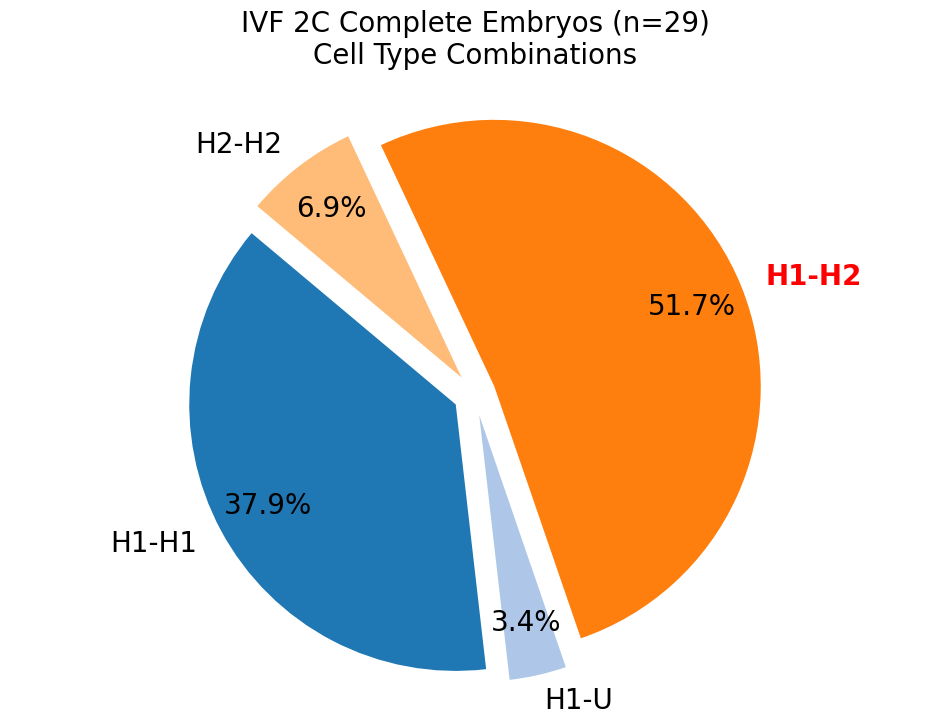

In [3]:
# IVF 2C blastomere type analysis — complete embryos only

from collections import defaultdict, Counter
import matplotlib.pyplot as plt
from IPython.display import SVG, display

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

input_file_name = "IVF-2C-blastomere-type.txt"
output_file_name = "IVF-2C-embryo_type_combinations_complete_only.txt"


# =========================
# 1. 读取并解析数据
# =========================
def read_and_parse(input_file_name):

    embryo_data = defaultdict(list)

    with open(input_file_name, 'r') as file:
        for line in file:
            parts = line.strip().split('\t')
            if len(parts) < 2:
                continue

            # IVF 胚胎ID取前三段
            embryo_id = parts[0].split('-')[:3]
            embryo_id_str = '-'.join(embryo_id)

            cell_type = parts[1].split('-')[2]

            embryo_data[embryo_id_str].append(cell_type)

    return embryo_data


# =========================
# 2. 只保留完整胚胎
# =========================
def count_complete_embryos(embryo_data):

    embryo_type_count = Counter()
    filtered_embryos = {}

    # ⭐ 新增：组合 -> embryo_id
    combination_to_embryos = defaultdict(list)

    for embryo_id, cell_types in embryo_data.items():

        if len(cell_types) != 2:
            continue

        if "FailedQC" in cell_types:
            continue

        filtered_embryos[embryo_id] = cell_types

        sorted_types = sorted(cell_types)

        if sorted_types[0] == sorted_types[1]:
            combination = f"{sorted_types[0]}-{sorted_types[0]}"
        else:
            combination = '-'.join(sorted_types)

        embryo_type_count[combination] += 1

        # ⭐ 记录 embryo
        combination_to_embryos[combination].append(embryo_id)

    total_embryos = len(filtered_embryos)

    return filtered_embryos, embryo_type_count, total_embryos, combination_to_embryos


# =========================
# 3. 写入结果文件
# =========================
def write_results(embryo_data, combination_counts, total_embryos, output_file_name):

    with open(output_file_name, 'w') as output_file:

        output_file.write("Complete embryos only (2 blastomeres, both passed QC)\n\n")

        for embryo_id, cell_types in embryo_data.items():

            sorted_types = sorted(cell_types)

            if sorted_types[0] == sorted_types[1]:
                combination = f"{sorted_types[0]}-{sorted_types[0]}"
            else:
                combination = '-'.join(sorted_types)

            output_file.write(f"{embryo_id}\t{combination}\n")

        output_file.write("\nType Combinations and Percentages:\n")

        for combination, count in combination_counts.items():
            percentage = (count / total_embryos) * 100
            output_file.write(f"{combination}: {count} ({percentage:.2f}%)\n")

    print("Results saved to:", output_file_name)


# =========================
# 4. 绘制饼图
# =========================
def plot_pie_chart(combination_counts, total_embryos):

    labels = list(combination_counts.keys())
    sizes = list(combination_counts.values())

    cmap = plt.get_cmap('tab20')
    colors = [cmap(i) for i in range(len(labels))]

    plt.figure(figsize=(12, 8))

    explode = [0.08] * len(labels)

    wedges, texts, autotexts = plt.pie(
        sizes,
        labels=labels,
        autopct='%1.1f%%',
        startangle=140,
        colors=colors,
        explode=explode,
        textprops={'fontsize': 20},
        pctdistance=0.8,
        labeldistance=1.1
    )

    # 强调 H1-H2
    for i, text in enumerate(texts):
        if labels[i] == "H1-H2":
            text.set_color('red')
            text.set_fontweight('bold')

    plt.axis('equal')

    plt.title(
        f'IVF 2C Complete Embryos (n={total_embryos})\nCell Type Combinations',
        fontsize=20,
        pad=20
    )
    plt.savefig('IVF_2C_embryo_type_count.svg', dpi=300, bbox_inches='tight', transparent=True)
    plt.show()


# =========================
# 5. 主函数
# =========================
def main():

    embryo_data = read_and_parse(input_file_name)

    filtered_embryos, combination_counts, total_embryos, combo_to_embryos = \
        count_complete_embryos(embryo_data)

    print("Number of complete embryos:", total_embryos)

    # =========================
    # 🔴 打印 H1-H2 胚胎
    # =========================
    target = "H1-H2"

    print("\n[RED EMBRYOS: H1-H2]\n")

    if target in combo_to_embryos:

        for eid in combo_to_embryos[target]:
            print(eid)

        print(f"\nTotal H1-H2 embryos: {len(combo_to_embryos[target])}")

    else:
        print("No H1-H2 embryos found")

    write_results(
        filtered_embryos,
        combination_counts,
        total_embryos,
        output_file_name
    )

    plot_pie_chart(combination_counts, total_embryos)


if __name__ == "__main__":
    main()

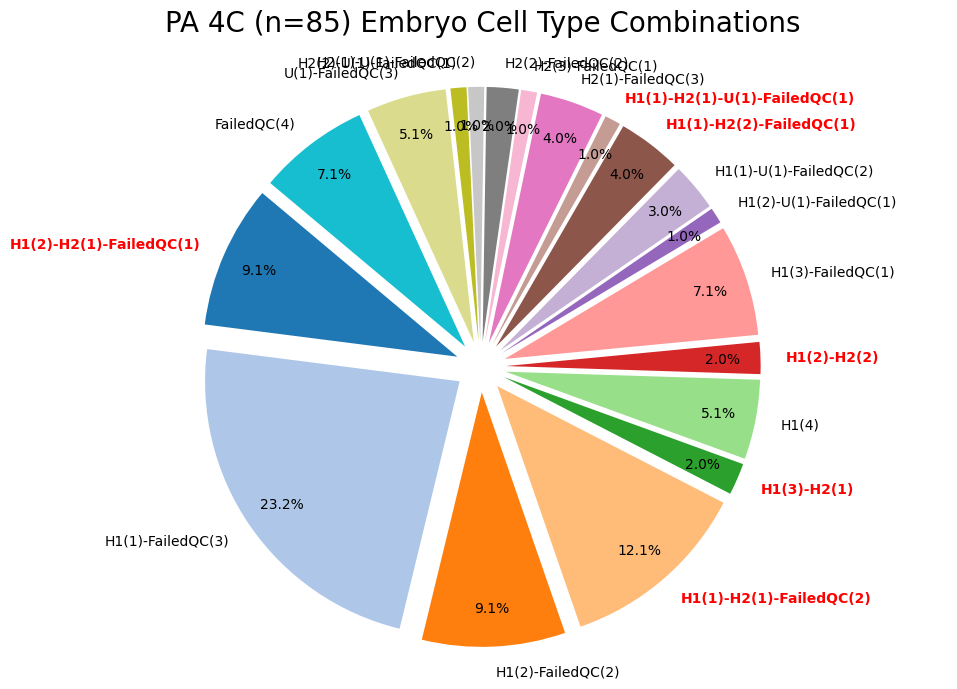

In [5]:
#hic
from collections import defaultdict, Counter
import matplotlib.pyplot as plt

# 假设文件名为 "PA-4C-blastomere-type.txt"
input_file_name = "PA-4C-blastomere-type.txt"
output_file_name = "PA-4C-embryo_type_combinations.txt"

# 读取文件并解析数据
def read_and_parse(input_file_name):
    with open(input_file_name, 'r') as file:
        lines = file.readlines()
    
    # 初始化一个字典来存储每个胚胎的细胞类型
    embryo_data = defaultdict(list)
    
    for line in lines:
        parts = line.strip().split('\t')
        if len(parts) < 2:
            continue
        embryo_id = parts[0].split('-')[:2]
        cell_type = parts[1].split('-')[2]
        # 将胚胎ID转换为字符串作为字典的键
        embryo_id_str = '-'.join(embryo_id)
        embryo_data[embryo_id_str].append(cell_type)
    
    return embryo_data

# 统计胚胎的细胞类型组合
def count_combination(embryo_data):
    embryo_type_count = Counter()
    embryo_sum = len(embryo_data)
    
    for cell_types in embryo_data.values():
        # 如果细胞数量不足4个，添加FailedQC作为缺失的细胞类型
        while len(cell_types) < 4:
            cell_types.append('FailedQC')
        # 统计每个细胞类型的数量
        type_count = Counter(cell_types)
        # 生成细胞类型组合字符串
        combination = '-'.join([f"{type}({count})" for type, count in type_count.items()])
        embryo_type_count[combination] += 1
    
    return embryo_data, embryo_type_count, embryo_sum

# 计算百分比并写入文件
def calculate_percentages_and_write(embryo_data, combination_counts, total_embryos, output_file_name):
    with open(output_file_name, 'w') as output_file:
        # 写入胚胎ID和对应的类型组合
        for embryo_id, cell_types in embryo_data.items():
            while len(cell_types) < 4:
                cell_types.append('FailedQC')
            type_count = Counter(cell_types)
            combination = '-'.join([f"{type}({count})" for type, count in type_count.items()])
            output_file.write(f"Embryo ID: {embryo_id}, Cell Types: {combination}\n")
        
        # 写入每种组合的数量和百分比
        output_file.write("\nType Combinations and Percentages:\n")
        for combination, count in combination_counts.items():
            percentage = (count / total_embryos) * 100
            output_file.write(f"{combination}: {count} ({percentage:.2f}%)\n")
    
    return combination_counts

# 绘制饼图
def plot_pie_chart(combination_counts):
    labels = combination_counts.keys()
    print(labels)
    sizes = combination_counts.values()
    cmap = plt.get_cmap('tab20')  # 获取Pastel1颜色映射对象
    colors = [cmap(i) for i in range(len(labels))]  # 生成颜色列表
    
    plt.figure(figsize=(10, 6))
    plt.pie(sizes, labels=labels, autopct='%1.1f%%', startangle=140, colors=colors)
    plt.axis('equal')  # 使饼图为圆形
    plt.title('PA 4C (n=85) Embryo Cell Type Combinations')
    plt.show()

def plot_pie_chart(combination_counts):
    labels = list(combination_counts.keys())
    sizes = combination_counts.values()
    cmap = plt.get_cmap('tab20')  # 获取tab20颜色映射对象
    colors = [cmap(i) for i in range(len(labels))]  # 生成颜色列表

    plt.figure(figsize=(12, 8))  # 增加图形大小
    explode = [0.1] * len(labels)  # 稍微分离每个部分
    wedges, texts, autotexts = plt.pie(sizes, labels=labels, autopct='%1.1f%%', startangle=140, 
                                        colors=colors, textprops={'fontsize': 10}, explode=explode, 
                                        pctdistance=0.85, labeldistance=1.1)

    # 设置特定标签的颜色和加粗
    for i, text in enumerate(texts):
        if "H1" in labels[i] and "H2" in labels[i]:
            text.set_color('red')
            text.set_fontweight('bold')

    plt.axis('equal')  # 使饼图为圆形
    plt.title('PA 4C (n=85) Embryo Cell Type Combinations', fontsize=20, pad=20)
    plt.show()
    
# 主函数
def main():
    embryo_data = read_and_parse(input_file_name)
    embryo_data, combination_counts, total_embryos = count_combination(embryo_data)
    combination_counts = calculate_percentages_and_write(embryo_data, combination_counts, total_embryos, output_file_name)
    plot_pie_chart(combination_counts)

if __name__ == "__main__":
    main()

Number of complete embryos: 9

[RED EMBRYOS: contain H1 + H2]


[H1(3)-H2(1)]
   4-167
   4-253

[H1(2)-H2(2)]
   4-195
   4-281

Total red embryos: 4
Results saved to: PA-4C-embryo_type_combinations_complete_only.txt


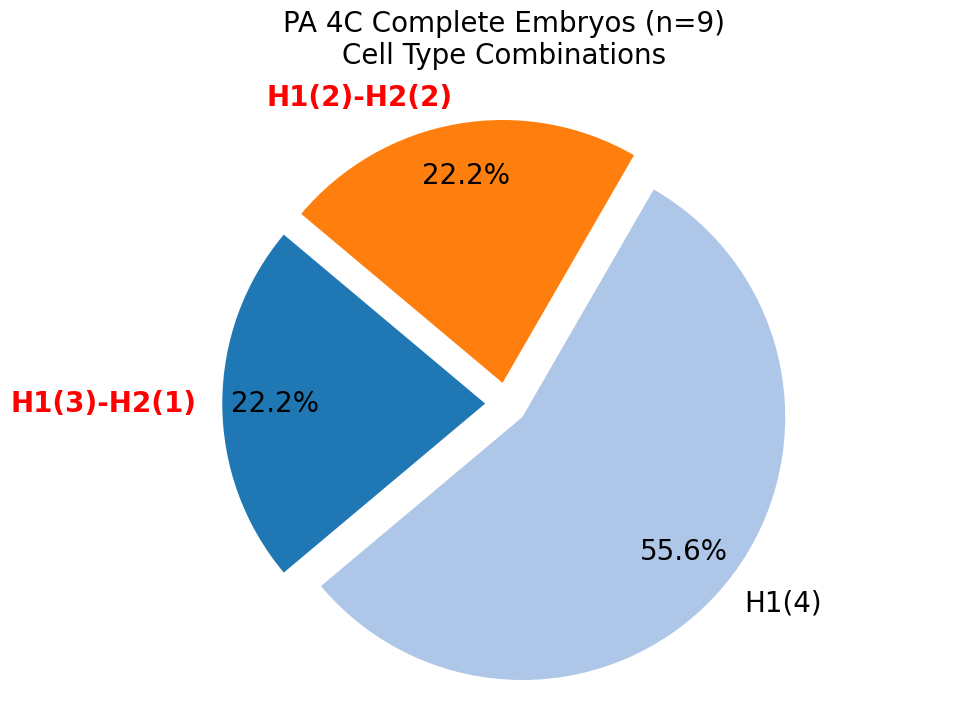

In [2]:
# PA 4C blastomere type analysis — complete embryos only
#hic
from collections import defaultdict, Counter
import matplotlib.pyplot as plt

input_file_name = "PA-4C-blastomere-type.txt"
output_file_name = "PA-4C-embryo_type_combinations_complete_only.txt"


# =========================
# 1. 读取并解析数据
# =========================
def read_and_parse(input_file_name):

    embryo_data = defaultdict(list)

    with open(input_file_name, 'r') as file:
        for line in file:
            parts = line.strip().split('\t')
            if len(parts) < 2:
                continue

            embryo_id = parts[0].split('-')[:2]
            embryo_id_str = '-'.join(embryo_id)

            cell_type = parts[1].split('-')[2]

            embryo_data[embryo_id_str].append(cell_type)

    return embryo_data


# =========================
# 2. 只保留完整 4C 胚胎
# =========================
def count_complete_embryos(embryo_data):

    embryo_type_count = Counter()
    filtered_embryos = {}

    # ⭐ 新增：组合 → embryo列表
    combination_to_embryos = defaultdict(list)

    for embryo_id, cell_types in embryo_data.items():

        if len(cell_types) != 4:
            continue

        if "FailedQC" in cell_types:
            continue

        filtered_embryos[embryo_id] = cell_types

        type_count = Counter(cell_types)
        sorted_types = sorted(type_count.items())

        combination = '-'.join(
            [f"{t}({c})" for t, c in sorted_types]
        )

        embryo_type_count[combination] += 1

        # ⭐ 记录
        combination_to_embryos[combination].append(embryo_id)

    total_embryos = len(filtered_embryos)

    return filtered_embryos, embryo_type_count, total_embryos, combination_to_embryos


# =========================
# 3. 写入结果
# =========================
def write_results(embryo_data, combination_counts, total_embryos, output_file_name):

    with open(output_file_name, 'w') as output_file:

        output_file.write("Complete embryos only (4 blastomeres, all passed QC)\n\n")

        for embryo_id, cell_types in embryo_data.items():

            type_count = Counter(cell_types)
            sorted_types = sorted(type_count.items())

            combination = '-'.join(
                [f"{t}({c})" for t, c in sorted_types]
            )

            output_file.write(f"{embryo_id}\t{combination}\n")

        output_file.write("\nType Combinations and Percentages:\n")

        for combination, count in combination_counts.items():
            percentage = (count / total_embryos) * 100
            output_file.write(f"{combination}: {count} ({percentage:.2f}%)\n")

    print("Results saved to:", output_file_name)


# =========================
# 4. 绘制饼图
# =========================
def plot_pie_chart(combination_counts, total_embryos):

    labels = list(combination_counts.keys())
    sizes = list(combination_counts.values())

    cmap = plt.get_cmap('tab20')
    colors = [cmap(i) for i in range(len(labels))]

    plt.figure(figsize=(12, 8))

    explode = [0.08] * len(labels)

    wedges, texts, autotexts = plt.pie(
        sizes,
        labels=labels,
        autopct='%1.1f%%',
        startangle=140,
        colors=colors,
        explode=explode,
        textprops={'fontsize': 20},
        pctdistance=0.8,
        labeldistance=1.1
    )

    # 强调包含 H1 和 H2 的组合
    for i, text in enumerate(texts):
        if "H1" in labels[i] and "H2" in labels[i]:
            text.set_color('red')
            text.set_fontweight('bold')

    plt.axis('equal')

    plt.title(
        f'PA 4C Complete Embryos (n={total_embryos})\nCell Type Combinations',
        fontsize=20,
        pad=20
    )
    plt.savefig('PA_4C_embryo_type_count.svg', dpi=300, bbox_inches='tight', transparent=True)
    plt.show()


# =========================
# 5. 主函数
# =========================
def main():

    embryo_data = read_and_parse(input_file_name)

    filtered_embryos, combination_counts, total_embryos, combo_to_embryos = \
        count_complete_embryos(embryo_data)

    print("Number of complete embryos:", total_embryos)

    # =========================
    # 🔴 打印 H1 + H2 胚胎
    # =========================
    print("\n[RED EMBRYOS: contain H1 + H2]\n")

    red_embryos = []

    for combo, eids in combo_to_embryos.items():

        if ("H1" in combo) and ("H2" in combo):

            print(f"\n[{combo}]")

            for eid in eids:
                print("  ", eid)
                red_embryos.append(eid)

    print(f"\nTotal red embryos: {len(red_embryos)}")

    # =========================
    # 正常输出
    # =========================
    write_results(
        filtered_embryos,
        combination_counts,
        total_embryos,
        output_file_name
    )

    plot_pie_chart(combination_counts, total_embryos)


if __name__ == "__main__":
    main()

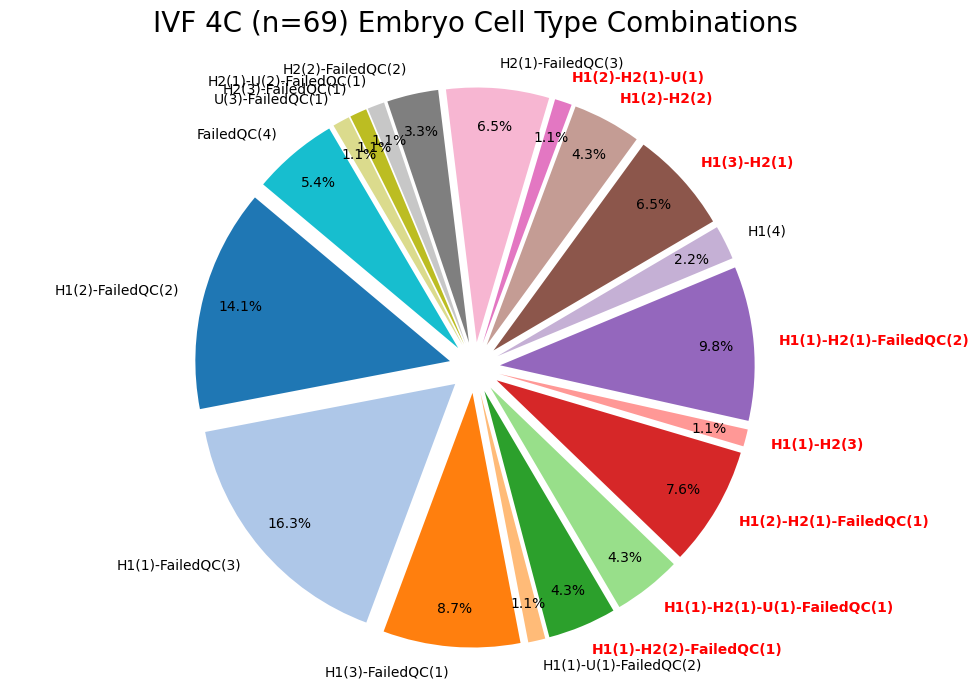

In [3]:
#hic IVF 4C
from collections import defaultdict, Counter
import matplotlib.pyplot as plt

# 假设文件名为 "IVF-4C-blastomere-type.txt"
input_file_name = "IVF-4C-blastomere-type.txt"
output_file_name = "IVF-4C-embryo_type_combinations.txt"

# 读取文件并解析数据
def read_and_parse(input_file_name):
    with open(input_file_name, 'r') as file:
        lines = file.readlines()
    
    # 初始化一个字典来存储每个胚胎的细胞类型
    embryo_data = defaultdict(list)
    
    for line in lines:
        parts = line.strip().split('\t')
        if len(parts) < 2:
            continue
        embryo_id = parts[0].split('-')[:3]
        cell_type = parts[1].split('-')[2]
        # 将胚胎ID转换为字符串作为字典的键
        embryo_id_str = '-'.join(embryo_id)
        embryo_data[embryo_id_str].append(cell_type)
    
    return embryo_data

# 生成细胞类型组合字符串
def generate_combination_label(cell_types):
    type_count = Counter(cell_types)
    combination = '-'.join([f"{type}({count})" for type, count in type_count.items()])
    return combination

# 统计胚胎的细胞类型组合
def count_combination(embryo_data):
    embryo_type_count = Counter()
    embryo_sum = len(embryo_data)
    
    for cell_types in embryo_data.values():
        # 如果细胞数量不足4个，添加FailedQC作为缺失的细胞类型
        while len(cell_types) < 4:
            cell_types.append('FailedQC')
        # 生成细胞类型组合字符串
        combination = generate_combination_label(cell_types)
        embryo_type_count[combination] += 1
    
    return embryo_data, embryo_type_count, embryo_sum

# 计算百分比并写入文件
def calculate_percentages_and_write(embryo_data, combination_counts, total_embryos, output_file_name):
    with open(output_file_name, 'w') as output_file:
        # 写入胚胎ID和对应的类型组合
        for embryo_id, cell_types in embryo_data.items():
            while len(cell_types) < 4:
                cell_types.append('FailedQC')
            combination = generate_combination_label(cell_types)
            output_file.write(f"Embryo ID: {embryo_id}, Cell Types: {combination}\n")
        
        # 写入每种组合的数量和百分比
        output_file.write("\nType Combinations and Percentages:\n")
        for combination, count in combination_counts.items():
            percentage = (count / total_embryos) * 100
            output_file.write(f"{combination}: {count} ({percentage:.2f}%)\n")
    
    return combination_counts

# 绘制饼图

def plot_pie_chart(combination_counts):
    labels = list(combination_counts.keys())
    sizes = combination_counts.values()
    cmap = plt.get_cmap('tab20')  # 获取tab20颜色映射对象
    colors = [cmap(i) for i in range(len(labels))]  # 生成颜色列表

    plt.figure(figsize=(12, 8))  # 增加图形大小
    explode = [0.1] * len(labels)  # 稍微分离每个部分
    wedges, texts, autotexts = plt.pie(sizes, labels=labels, autopct='%1.1f%%', startangle=140, 
                                        colors=colors, textprops={'fontsize': 10}, explode=explode, 
                                        pctdistance=0.85, labeldistance=1.1)

    # 设置特定标签的颜色和加粗
    for i, text in enumerate(texts):
        if "H1" in labels[i] and "H2" in labels[i]:
            text.set_color('red')
            text.set_fontweight('bold')

    plt.axis('equal')  # 使饼图为圆形
    plt.title('IVF 4C (n=69) Embryo Cell Type Combinations', fontsize=20, pad=20)
    plt.show()
# 主函数
def main():
    embryo_data = read_and_parse(input_file_name)
    embryo_data, combination_counts, total_embryos = count_combination(embryo_data)
    combination_counts = calculate_percentages_and_write(embryo_data, combination_counts, total_embryos, output_file_name)
    plot_pie_chart(combination_counts)

if __name__ == "__main__":
    main()


Number of complete embryos: 14

[RED EMBRYOS: H1 + H2 CONTAINING]


[H1(1)-H2(3)]
   IVF-4-121

[H1(3)-H2(1)]
   IVF-4-31
   IVF-4-44
   IVF-4-72
   IVF-4-84
   IVF-4-89
   IVF-4-95

[H1(2)-H2(2)]
   IVF-4-54
   IVF-4-63
   IVF-4-91
   IVF-4-96

[H1(2)-H2(1)-U(1)]
   IVF-4-85

Total red embryos: 12
Results saved to: IVF-4C-embryo_type_combinations_complete_only.txt


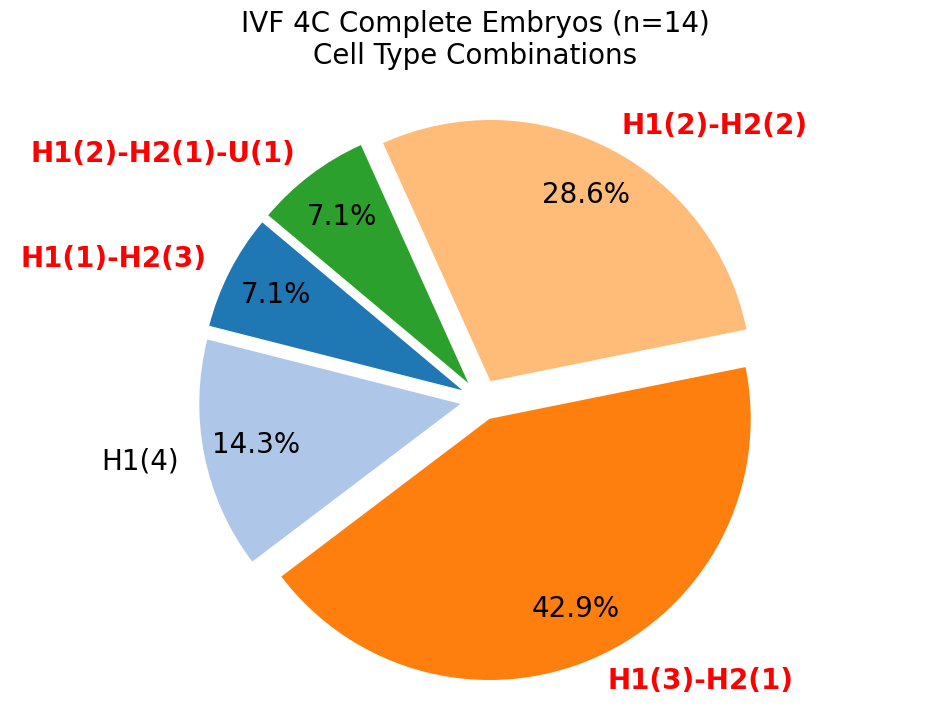

In [4]:
# IVF 4C blastomere type analysis — complete embryos only

from collections import defaultdict, Counter
import matplotlib.pyplot as plt
from IPython.display import SVG, display

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

input_file_name = "IVF-4C-blastomere-type.txt"
output_file_name = "IVF-4C-embryo_type_combinations_complete_only.txt"


# =========================
# 1. 读取并解析数据
# =========================
def read_and_parse(input_file_name):

    embryo_data = defaultdict(list)

    with open(input_file_name, 'r') as file:
        for line in file:
            parts = line.strip().split('\t')
            if len(parts) < 2:
                continue

            # IVF 胚胎ID取前三段
            embryo_id = parts[0].split('-')[:3]
            embryo_id_str = '-'.join(embryo_id)

            cell_type = parts[1].split('-')[2]

            embryo_data[embryo_id_str].append(cell_type)

    return embryo_data


# =========================
# 2. 只保留完整 4C 胚胎
# =========================
def count_complete_embryos(embryo_data):

    embryo_type_count = Counter()
    filtered_embryos = {}

    # ⭐ 新增：组合 → embryo list
    combination_to_embryos = defaultdict(list)

    for embryo_id, cell_types in embryo_data.items():

        if len(cell_types) != 4:
            continue

        if "FailedQC" in cell_types:
            continue

        filtered_embryos[embryo_id] = cell_types

        type_count = Counter(cell_types)

        sorted_types = sorted(type_count.items())

        combination = '-'.join(
            [f"{t}({c})" for t, c in sorted_types]
        )

        embryo_type_count[combination] += 1

        # ⭐ 记录 embryo
        combination_to_embryos[combination].append(embryo_id)

    total_embryos = len(filtered_embryos)

    return filtered_embryos, embryo_type_count, total_embryos, combination_to_embryos


# =========================
# 3. 写入结果文件
# =========================
def write_results(embryo_data, combination_counts, total_embryos, output_file_name):

    with open(output_file_name, 'w') as output_file:

        output_file.write("Complete embryos only (4 blastomeres, all passed QC)\n\n")

        for embryo_id, cell_types in embryo_data.items():

            type_count = Counter(cell_types)
            sorted_types = sorted(type_count.items())

            combination = '-'.join(
                [f"{t}({c})" for t, c in sorted_types]
            )

            output_file.write(f"{embryo_id}\t{combination}\n")

        output_file.write("\nType Combinations and Percentages:\n")

        for combination, count in combination_counts.items():
            percentage = (count / total_embryos) * 100
            output_file.write(f"{combination}: {count} ({percentage:.2f}%)\n")

    print("Results saved to:", output_file_name)


# =========================
# 4. 绘制饼图
# =========================
def plot_pie_chart(combination_counts, total_embryos):

    labels = list(combination_counts.keys())
    sizes = list(combination_counts.values())

    cmap = plt.get_cmap('tab20')
    colors = [cmap(i) for i in range(len(labels))]

    plt.figure(figsize=(12, 8))

    explode = [0.08] * len(labels)

    wedges, texts, autotexts = plt.pie(
        sizes,
        labels=labels,
        autopct='%1.1f%%',
        startangle=140,
        colors=colors,
        explode=explode,
        textprops={'fontsize': 20},
        pctdistance=0.8,
        labeldistance=1.1
    )

    # 强调同时含 H1 和 H2 的组合
    for i, text in enumerate(texts):
        if "H1" in labels[i] and "H2" in labels[i]:
            text.set_color('red')
            text.set_fontweight('bold')

    plt.axis('equal')

    plt.title(
        f'IVF 4C Complete Embryos (n={total_embryos})\nCell Type Combinations',
        fontsize=20,
        pad=20
    )
    plt.savefig('IVF_4C_embryo_type_count.svg', dpi=300, bbox_inches='tight', transparent=True)
    plt.show()


# =========================
# 5. 主函数
# =========================
def main():

    embryo_data = read_and_parse(input_file_name)

    filtered_embryos, combination_counts, total_embryos, combo_to_embryos = \
        count_complete_embryos(embryo_data)

    print("Number of complete embryos:", total_embryos)

    # =========================
    # 🔴 打印 H1 + H2 胚胎
    # =========================
    print("\n[RED EMBRYOS: H1 + H2 CONTAINING]\n")

    red_list = []

    for combo, eids in combo_to_embryos.items():

        if ("H1" in combo) and ("H2" in combo):

            red_list.extend(eids)

            print(f"\n[{combo}]")
            for eid in eids:
                print("  ", eid)

    print(f"\nTotal red embryos: {len(red_list)}")

    write_results(
        filtered_embryos,
        combination_counts,
        total_embryos,
        output_file_name
    )

    plot_pie_chart(combination_counts, total_embryos)


if __name__ == "__main__":
    main()

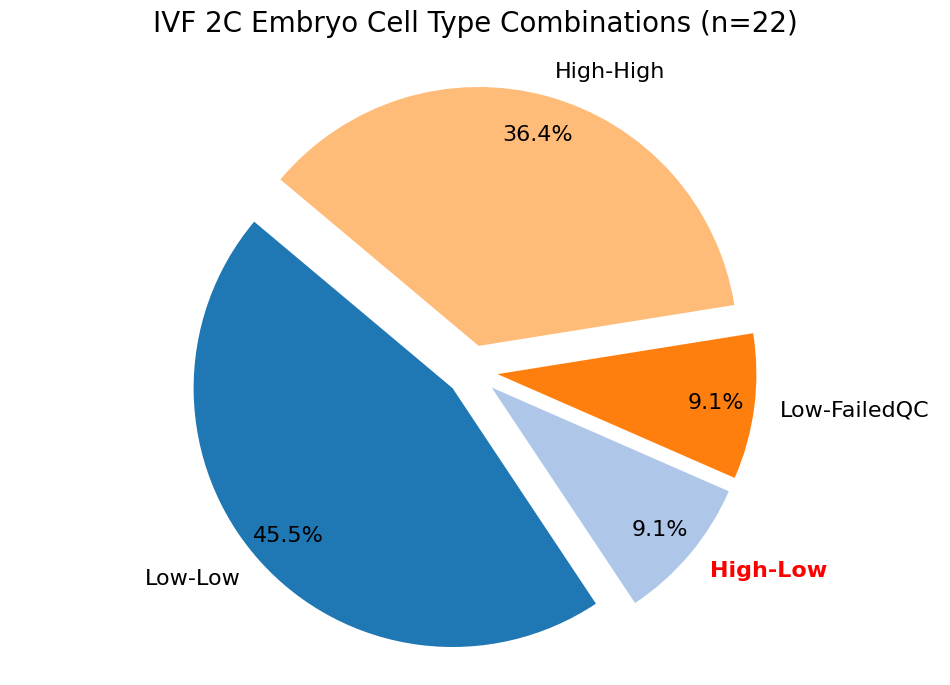

In [15]:
#IVF 2C RNA
from collections import defaultdict, Counter
import matplotlib.pyplot as plt

# =============================
# Function: plot pie chart
# =============================
def plot_pie_chart(combination_counts, title):
    labels = list(combination_counts.keys())
    sizes = combination_counts.values()
    cmap = plt.get_cmap('tab20')  
    colors = [cmap(i) for i in range(len(labels))]

    plt.figure(figsize=(12, 8))
    explode = [0.1] * len(labels) 
    wedges, texts, autotexts = plt.pie(
        sizes, labels=labels, autopct='%1.1f%%', startangle=140,
        colors=colors, textprops={'fontsize': 16}, explode=explode,
        pctdistance=0.85, labeldistance=1.1
    )

    # ✅ 高亮 H1-H2 (你可以改成 Toti-High / Toti-Low 的逻辑)
    for i, text in enumerate(texts):
        if "High" in labels[i] and "Low" in labels[i]:
            text.set_color('red')
            text.set_fontweight('bold')

    plt.axis('equal')
    plt.title(title, fontsize=20, pad=20)
    plt.show()
  
# =============================
# Processing data
# =============================
input_file = "IVF-2C-RNA-blastomere-type.txt"
output_file = "IVF-2C-RNA-embryo_type_combinations.txt"

embryo_data = defaultdict(list)

# 读取输入
with open(input_file, 'r') as f:
    for line in f:
        cell, label = line.strip().split('\t')
        embryo_id = '.'.join(cell.split('.')[:3]) 
        cell_type = label.split('-')[-1]  

        embryo_data[embryo_id].append(cell_type)

# 统计组合
comb_counts = Counter()
with open(output_file, 'w') as out:
    for embryo, types in embryo_data.items():
        types = sorted(types)  

        # ✅ 如果只有 1 个补 FailedQC
        if len(types) == 1:
            combo = f"{types[0]}-FailedQC"
        else:
            combo = "-".join(types)

        comb_counts[combo] += 1
        out.write(f"{embryo}\t{combo}\n")

    # 写组合统计
    total = len(embryo_data)
    out.write("\nCombination counts:\n")
    for k, v in comb_counts.items():
        out.write(f"{k}: {v} ({v/total*100:.2f}%)\n")

# =============================
# Plot
# =============================
plot_pie_chart(
    comb_counts, 
    title=f"IVF 2C Embryo Cell Type Combinations (n={total})"
)
plt.savefig('IVF_2C_RNA_Cell_Type_Combinations.svg', dpi=300, bbox_inches='tight', transparent=True)

Embryos kept for analysis: 20


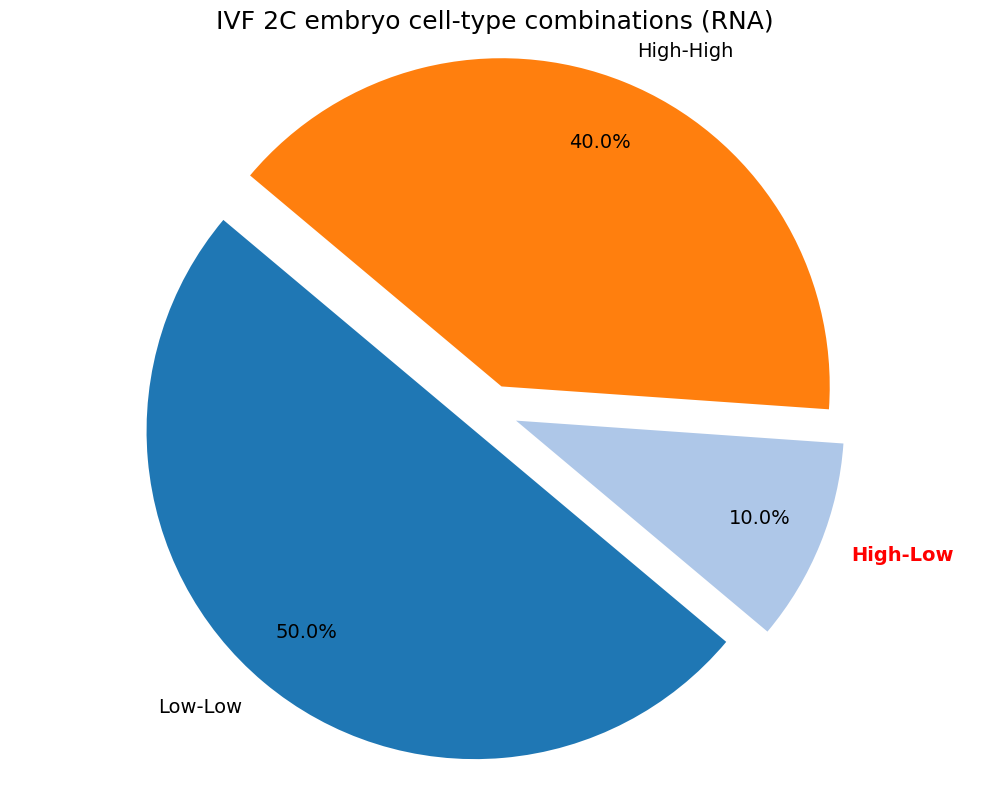

In [25]:
##IVF 2C RNA 剔除未通过 QC 的胚胎
from collections import defaultdict, Counter
import matplotlib.pyplot as plt
from IPython.display import SVG, display

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'
# =============================
# Parameters
# =============================
EXPECTED_CELL_NUM = 2   # IVF 2C
input_file = "IVF-2C-RNA-blastomere-type.txt"
output_file = "IVF-2C-RNA-embryo_type_combinations.txt"

# =============================
# Function: plot pie chart
# =============================
def plot_pie_chart(combination_counts, title, highlight_combos=None):
    """
    highlight_combos: list of strings, e.g., ["High-Low", "Low-High"]
    """
    if highlight_combos is None:
        highlight_combos = ["High-Low", "Low-High"]

    labels = list(combination_counts.keys())
    sizes = list(combination_counts.values())

    cmap = plt.get_cmap('tab20')
    colors = [cmap(i) for i in range(len(labels))]

    plt.figure(figsize=(10, 8))
    explode = [0.08] * len(labels)

    wedges, texts, autotexts = plt.pie(
        sizes,
        labels=labels,
        autopct='%1.1f%%',
        startangle=140,
        colors=colors,
        explode=explode,
        pctdistance=0.8,
        labeldistance=1.1,
        textprops={'fontsize': 14}
    )

    # ✅ 高亮指定组合
    for i, text in enumerate(texts):
        if labels[i] in highlight_combos:
            text.set_color('red')
            text.set_fontweight('bold')

    plt.axis('equal')
    plt.title(title, fontsize=18)
    plt.tight_layout()
    plt.savefig('IVF_2C_RNA_Cell_Type_Combinations.svg', dpi=300, bbox_inches='tight', transparent=True)
    plt.show()


# =============================
# Read data
# =============================
embryo_data = defaultdict(list)

with open(input_file) as f:
    for line in f:
        cell, label = line.strip().split('\t')
        embryo_id = '.'.join(cell.split('.')[:3])
        cell_type = label.split('-')[-1]
        embryo_data[embryo_id].append(cell_type)

# =============================
# Count combinations (QC filtered)
# =============================
comb_counts = Counter()
kept_embryos = 0

with open(output_file, 'w') as out:
    for embryo, types in embryo_data.items():

        # ❌ 剔除未通过 QC 的胚胎
        if len(types) != EXPECTED_CELL_NUM:
            continue

        kept_embryos += 1
        types = sorted(types)
        combo = "-".join(types)

        comb_counts[combo] += 1
        out.write(f"{embryo}\t{combo}\n")

    out.write("\nCombination counts:\n")
    for k, v in comb_counts.items():
        out.write(f"{k}: {v} ({v/kept_embryos*100:.2f}%)\n")

print(f"Embryos kept for analysis: {kept_embryos}")

# =============================
# Plot
# =============================
plot_pie_chart(
    comb_counts,
    title=f"IVF 2C embryo cell-type combinations (RNA)"
)


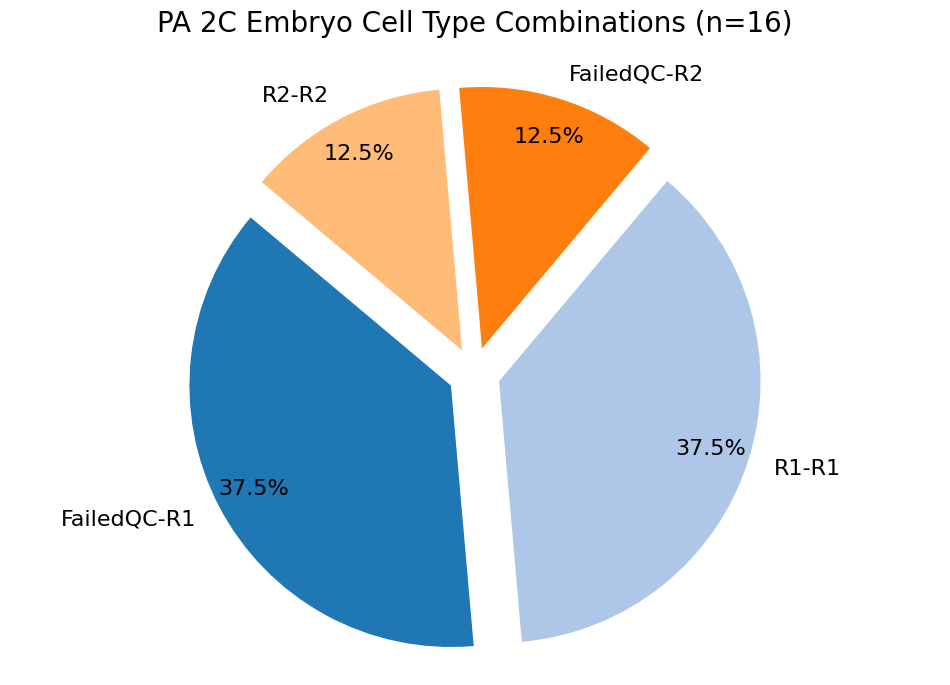

In [10]:
#PA 2C RNA
from collections import defaultdict, Counter
import matplotlib.pyplot as plt

# =============================
# Function: plot pie chart
# =============================
def plot_pie_chart(combination_counts, title):
    labels = list(combination_counts.keys())
    sizes = combination_counts.values()
    cmap = plt.get_cmap('tab20')
    colors = [cmap(i) for i in range(len(labels))]

    plt.figure(figsize=(12, 8))
    explode = [0.1] * len(labels)
    wedges, texts, autotexts = plt.pie(
        sizes, labels=labels, autopct='%1.1f%%', startangle=140,
        colors=colors, textprops={'fontsize': 16}, explode=explode,
        pctdistance=0.85, labeldistance=1.1
    )

    # ✅ 高亮 R1-R2 组合
    for i, text in enumerate(texts):
        if "R1" in labels[i] and "R2" in labels[i]:
            text.set_color('red')
            text.set_fontweight('bold')

    plt.axis('equal')
    plt.title(title, fontsize=20, pad=20)
    plt.show()


# =============================
# Processing PA-2C data
# =============================
input_file = "PA-2C-RNA-blastomere-type.txt"
output_file = "PA-2C-RNA-embryo_type_combinations.txt"

embryo_data = defaultdict(list)

with open(input_file, 'r') as f:
    for line in f:
        cell, label = line.strip().split('\t')
        # ✅ 新数据 embryo ID = 前两段，比如 R2.41
        embryo_id = '.'.join(cell.split('.')[:2])
        cell_type = label.split('-')[-1]

        embryo_data[embryo_id].append(cell_type)

# 统计组合
comb_counts = Counter()

with open(output_file, 'w') as out:
    for embryo, types in embryo_data.items():
        types = sorted(types)

        # ✅ 如果只有 1 个补 FailedQC
        if len(types) == 1:
            combo = f"{types[0]}-FailedQC"
        else:
            combo = "-".join(types)

        comb_counts[combo] += 1
        out.write(f"{embryo}\t{combo}\n")

    total = len(embryo_data)
    out.write("\nCombination counts:\n")
    for k, v in comb_counts.items():
        out.write(f"{k}: {v} ({v/total*100:.2f}%)\n")


# =============================
# Plot
# =============================
plot_pie_chart(
    comb_counts,
    title=f"PA 2C Embryo Cell Type Combinations (n={total})"
)


Embryos kept for analysis: 8


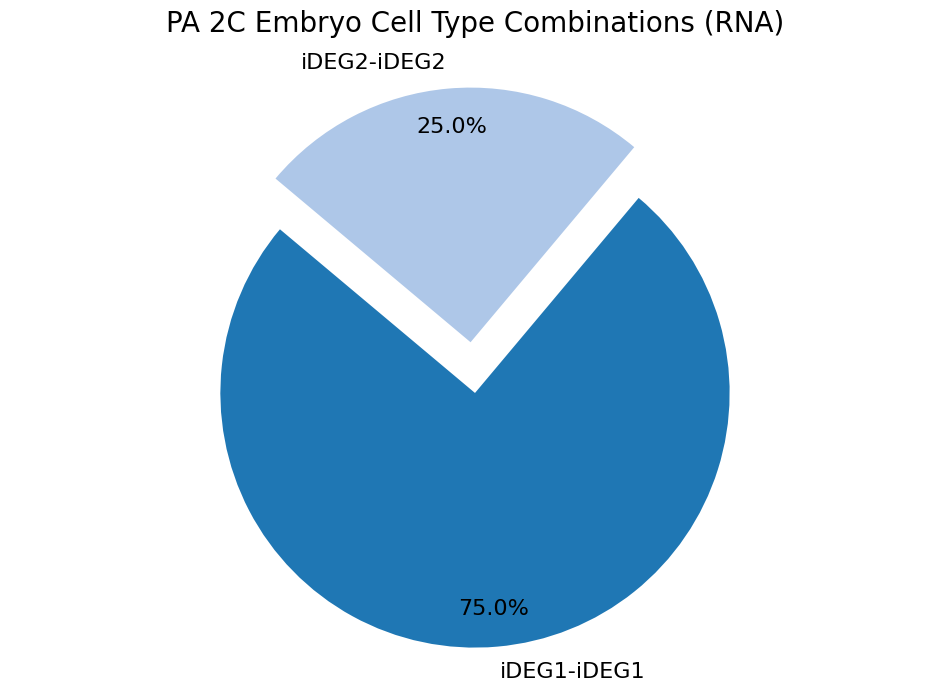

In [1]:
##PA 2C RNA 剔除未通过 QC 的胚胎
from collections import defaultdict, Counter
import matplotlib.pyplot as plt
from IPython.display import SVG, display

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'
# =============================
# Parameters
# =============================
EXPECTED_CELL_NUM = 2   # 2C 阶段
input_file = "PA-2C-RNA-blastomere-type_rmFailedQC.txt"
output_file = "PA-2C-RNA-embryo_type_combinations.txt"

# =============================
# Function: plot pie chart
# =============================
def plot_pie_chart(combination_counts, title, highlight_combos=None):
    if highlight_combos is None:
        highlight_combos = []

    labels = list(combination_counts.keys())
    sizes = list(combination_counts.values())

    cmap = plt.get_cmap('tab20')
    colors = [cmap(i) for i in range(len(labels))]

    plt.figure(figsize=(12, 8))
    explode = [0.1] * len(labels)

    wedges, texts, autotexts = plt.pie(
        sizes,
        labels=labels,
        autopct='%1.1f%%',
        startangle=140,
        colors=colors,
        explode=explode,
        pctdistance=0.85,
        labeldistance=1.1,
        textprops={'fontsize': 16}
    )

    # 高亮指定组合
    for i, text in enumerate(texts):
        if labels[i] in highlight_combos:
            text.set_color('red')
            text.set_fontweight('bold')

    plt.axis('equal')
    plt.title(title, fontsize=20, pad=20)
    plt.savefig('PA_2C_RNA_Cell_Type_Combinations.svg', dpi=300, bbox_inches='tight', transparent=True)
    plt.show()


# =============================
# Processing PA-2C data
# =============================
embryo_data = defaultdict(list)

with open(input_file, 'r') as f:
    for line in f:
        cell, label = line.strip().split('\t')
        # embryo ID = 前两段
        embryo_id = '.'.join(cell.split('.')[:2])
        cell_type = label.split('-')[-1]
        embryo_data[embryo_id].append(cell_type)

# =============================
# Count combinations (QC filtered)
# =============================
comb_counts = Counter()
kept_embryos = 0

with open(output_file, 'w') as out:
    for embryo, types in embryo_data.items():

        # ❌ 严格剔除未通过 QC 的胚胎
        if len(types) != EXPECTED_CELL_NUM:
            continue  # 不生成 FailedQC

        kept_embryos += 1
        types = sorted(types)
        combo = "-".join(types)

        comb_counts[combo] += 1
        out.write(f"{embryo}\t{combo}\n")

    out.write("\nCombination counts:\n")
    for k, v in comb_counts.items():
        out.write(f"{k}: {v} ({v/kept_embryos*100:.2f}%)\n")

print(f"Embryos kept for analysis: {kept_embryos}")

# =============================
# Plot
# =============================
highlight_combos = ["iDEG1-iDEG2"]  # 高亮出现分化的组合
plot_pie_chart(
    comb_counts,
    title=f"PA 2C Embryo Cell Type Combinations (RNA)",
    highlight_combos=highlight_combos
)


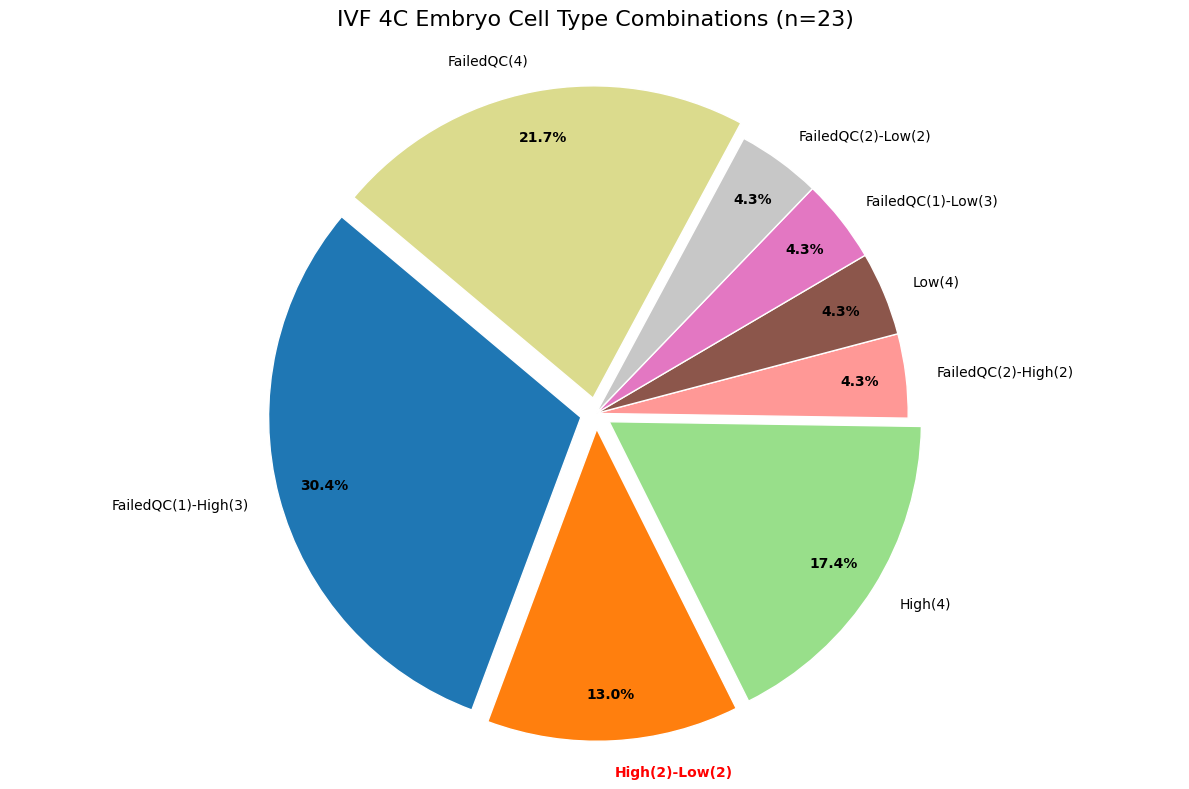

Processed 23 embryos. Output written to IVF-4C-RNA-embryo_type_combinations.txt.
Highlighted Embryo IDs (combinations with both High and Low):
- IVF.R4.13
- IVF.RC.4.2
- IVF.RC.4.7


In [16]:
#IVF 4C RNA
from collections import defaultdict, Counter
import matplotlib.pyplot as plt

input_file_name = "IVF-4C-RNA-blastomere-type.txt"
output_file_name = "IVF-4C-RNA-embryo_type_combinations.txt"

# 读取文件并解析数据
def read_and_parse(input_file_name):
    embryo_data = defaultdict(list)
    with open(input_file_name, 'r') as file:
        lines = file.readlines()
    
    for line in lines:
        parts = line.strip().split('\t')
        if len(parts) < 2:
            continue
        cell_id = parts[0].strip()
        cell_type = parts[1].strip().split('-')[2]  # Extract 'High', 'Low', or 'FailedQC'
        
        # Extract embryo prefix by joining all but the last part after splitting by '.'
        split_id = cell_id.split('.')
        if len(split_id) > 1:
            embryo_prefix = '.'.join(split_id[:-1])
            embryo_data[embryo_prefix].append(cell_type)
    
    return embryo_data

# 生成细胞类型组合字符串（按类型字母顺序排序以确保一致性）
def generate_combination_label(cell_types):
    type_count = Counter(cell_types)
    sorted_types = sorted(type_count.keys())  # Sort keys alphabetically for consistency
    combination = '-'.join([f"{t}({type_count[t]})" for t in sorted_types])
    return combination

# 统计胚胎的细胞类型组合（不修改原列表）
def count_combinations(embryo_data):
    combination_counts = Counter()
    total_embryos = len(embryo_data)
    
    for cell_types in embryo_data.values():
        # Create a copy to avoid modifying the original list
        temp_types = cell_types[:]
        # Pad with 'FailedQC' if fewer than 4 cells
        while len(temp_types) < 4:
            temp_types.append('FailedQC')
        # Generate combination label
        combination = generate_combination_label(temp_types)
        combination_counts[combination] += 1
    
    return combination_counts, total_embryos

# 计算百分比并写入文件
def write_output(embryo_data, combination_counts, total_embryos, output_file_name):
    with open(output_file_name, 'w') as output_file:
        # Write per-embryo details
        output_file.write("Per-Embryo Cell Type Combinations:\n")
        for embryo_id, cell_types in sorted(embryo_data.items()):  # Sort for consistent output
            temp_types = cell_types[:]
            while len(temp_types) < 4:
                temp_types.append('FailedQC')
            combination = generate_combination_label(temp_types)
            output_file.write(f"Embryo ID: {embryo_id}, Combination: {combination}\n")
        
        # Write summary
        output_file.write(f"\nSummary (Total Embryos: {total_embryos}):\n")
        for combination, count in sorted(combination_counts.items()):  # Sort for consistent output
            percentage = (count / total_embryos) * 100
            output_file.write(f"{combination}: {count} ({percentage:.2f}%)\n")
    
    return combination_counts

# 绘制饼图
def plot_pie_chart(combination_counts, total_embryos):
    if not combination_counts:
        print("No data to plot.")
        return
    
    labels = list(combination_counts.keys())
    sizes = list(combination_counts.values())
    cmap = plt.get_cmap('tab20')
    colors = [cmap(i / len(labels)) for i in range(len(labels))]

    plt.figure(figsize=(12, 8))
    explode = [0.05 if size / sum(sizes) > 0.05 else 0 for size in sizes]  # Slight explode for larger slices
    wedges, texts, autotexts = plt.pie(
        sizes, 
        labels=labels, 
        autopct='%1.1f%%', 
        startangle=140, 
        colors=colors, 
        explode=explode, 
        pctdistance=0.85, 
        textprops={'fontsize': 10},
        wedgeprops={'edgecolor': 'white', 'linewidth': 1}
    )
        # 设置特定标签的颜色和加粗
    for i, text in enumerate(texts):
        if "High" in labels[i] and "Low" in labels[i]:
            text.set_color('red')
            text.set_fontweight('bold')
            
    # Improve text readability
    for autotext in autotexts:
        autotext.set_color('black')
        autotext.set_fontweight('bold')

    plt.axis('equal')
    plt.title(f'IVF 4C Embryo Cell Type Combinations (n={total_embryos})', fontsize=16, pad=20)
    plt.tight_layout()
    plt.show()

# 打印需要高亮的胚胎ID（即组合中同时包含High和Low的胚胎）
def print_highlighted_embryos(embryo_data):
    highlighted_embryos = []
    for embryo_id, cell_types in sorted(embryo_data.items()):
        temp_types = cell_types[:]
        while len(temp_types) < 4:
            temp_types.append('FailedQC')
        combination = generate_combination_label(temp_types)
        if "High" in combination and "Low" in combination:
            highlighted_embryos.append(embryo_id)
    
    if highlighted_embryos:
        print("Highlighted Embryo IDs (combinations with both High and Low):")
        for eid in highlighted_embryos:
            print(f"- {eid}")
    else:
        print("No embryos with both High and Low combinations found.")
    
    return highlighted_embryos

    
# 主函数
def main():
    embryo_data = read_and_parse(input_file_name)
    combination_counts, total_embryos = count_combinations(embryo_data)
    write_output(embryo_data, combination_counts, total_embryos, output_file_name)
    plot_pie_chart(combination_counts, total_embryos)
    print(f"Processed {total_embryos} embryos. Output written to {output_file_name}.")
    
    # 新增：打印高亮胚胎ID
    print_highlighted_embryos(embryo_data)

if __name__ == "__main__":
    main()

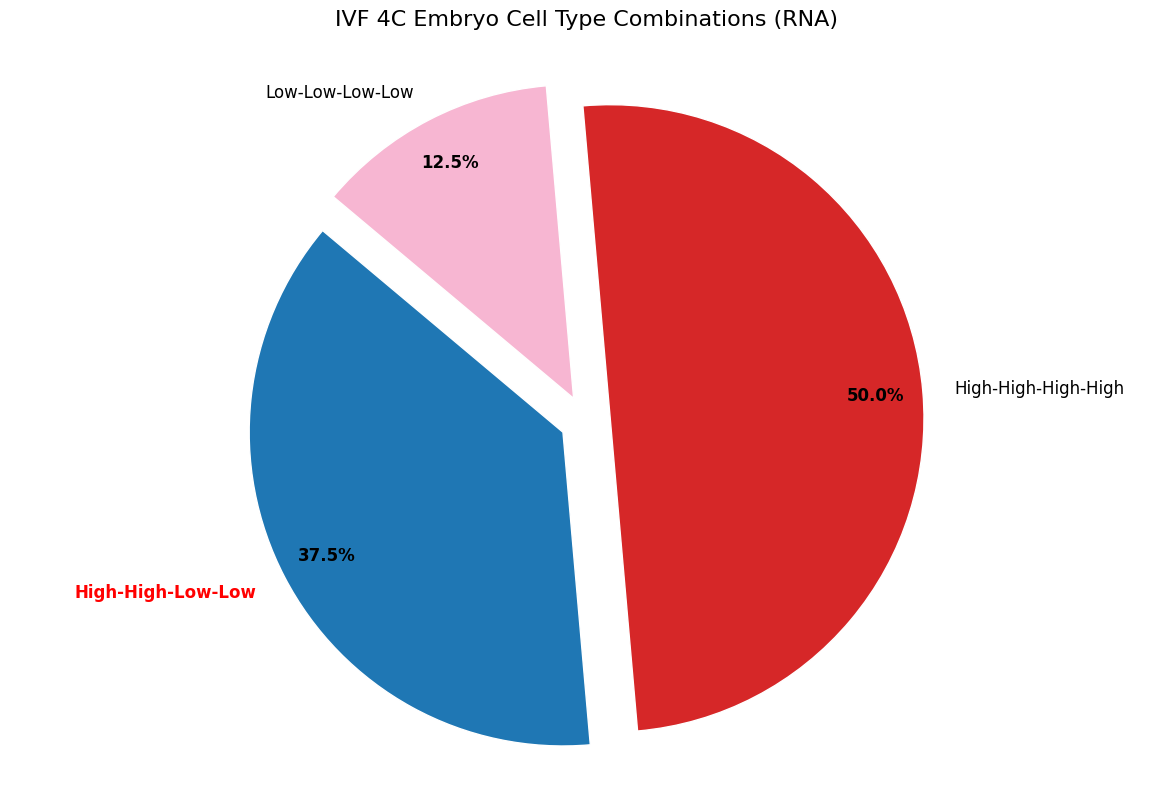

Highlighted Embryo IDs (both High and Low present):
- IVF.R4.13
- IVF.RC.4.2
- IVF.RC.4.7
Processed 8 embryos. Output written to IVF-4C-RNA-embryo_type_combinations.txt.


In [23]:
##IVF 4C RNA 剔除未通过 QC 的胚胎
from collections import defaultdict, Counter
import matplotlib.pyplot as plt
from IPython.display import SVG, display

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

input_file_name = "IVF-4C-RNA-blastomere-type_rmFailedQC.txt"
output_file_name = "IVF-4C-RNA-embryo_type_combinations.txt"
EXPECTED_CELL_NUM = 4  # 4C 阶段

# =============================
# 读取文件并解析数据
# =============================
def read_and_parse(input_file_name):
    embryo_data = defaultdict(list)
    with open(input_file_name, 'r') as file:
        for line in file:
            parts = line.strip().split('\t')
            if len(parts) < 2:
                continue
            cell_id = parts[0].strip()
            cell_type = parts[1].strip().split('-')[-1]  # Extract 'High' or 'Low'

            # Extract embryo prefix by joining all but the last part
            split_id = cell_id.split('.')
            if len(split_id) > 1:
                embryo_prefix = '.'.join(split_id[:-1])
                embryo_data[embryo_prefix].append(cell_type)

    return embryo_data

# =============================
# 生成组合字符串
# =============================
def generate_combination_label(cell_types):
    sorted_types = sorted(cell_types)
    combination = '-'.join(sorted_types)
    return combination

# =============================
# 统计组合（严格 QC，未通过 QC 剔除）
# =============================
def count_combinations(embryo_data):
    combination_counts = Counter()
    kept_embryos = 0

    # 创建新字典剔除未通过 QC 的胚胎
    filtered_embryo_data = dict()
    for embryo_id, cell_types in embryo_data.items():
        if len(cell_types) != EXPECTED_CELL_NUM:
            continue  # 剔除未通过 QC 的胚胎
        kept_embryos += 1
        combination = generate_combination_label(cell_types)
        combination_counts[combination] += 1
        filtered_embryo_data[embryo_id] = cell_types

    return filtered_embryo_data, combination_counts, kept_embryos

# =============================
# 输出文件
# =============================
def write_output(filtered_embryo_data, combination_counts, kept_embryos, output_file_name):
    with open(output_file_name, 'w') as out:
        out.write("Per-Embryo Cell Type Combinations (QC passed):\n")
        for embryo_id, cell_types in sorted(filtered_embryo_data.items()):
            combination = generate_combination_label(cell_types)
            out.write(f"{embryo_id}\t{combination}\n")

        out.write(f"\nSummary (Total embryos passed QC: {kept_embryos}):\n")
        for combination, count in sorted(combination_counts.items()):
            percentage = count / kept_embryos * 100
            out.write(f"{combination}: {count} ({percentage:.2f}%)\n")

# =============================
# 绘制饼图
# =============================
def plot_pie_chart(combination_counts, kept_embryos):
    if not combination_counts:
        print("No data to plot.")
        return

    labels = list(combination_counts.keys())
    sizes = list(combination_counts.values())
    cmap = plt.get_cmap('tab20')
    colors = [cmap(i / len(labels)) for i in range(len(labels))]

    plt.figure(figsize=(12, 8))
    explode = [0.08] * len(labels)  # 每片稍微分离

    wedges, texts, autotexts = plt.pie(
        sizes,
        labels=labels,
        autopct='%1.1f%%',
        startangle=140,
        colors=colors,
        explode=explode,
        pctdistance=0.85,
        textprops={'fontsize': 12},
        wedgeprops={'edgecolor': 'white', 'linewidth': 1}
    )

    # 高亮出现分化组合（同时包含 High 和 Low）
    for i, text in enumerate(texts):
        if "High" in labels[i] and "Low" in labels[i]:
            text.set_color('red')
            text.set_fontweight('bold')

    # 自动加粗百分比
    for autotext in autotexts:
        autotext.set_fontweight('bold')

    plt.axis('equal')
    plt.title(f"IVF 4C Embryo Cell Type Combinations (RNA)", fontsize=16, pad=20)
    plt.tight_layout()
    plt.savefig('IVF_4C_RNA_Cell_Type_Combinations.svg', dpi=300, bbox_inches='tight', transparent=True)
    plt.show()
    
# =============================
# 打印高亮胚胎 ID
# =============================
def print_highlighted_embryos(filtered_embryo_data):
    highlighted = []
    for embryo_id, cell_types in filtered_embryo_data.items():
        if "High" in cell_types and "Low" in cell_types:
            highlighted.append(embryo_id)
    if highlighted:
        print("Highlighted Embryo IDs (both High and Low present):")
        for eid in highlighted:
            print(f"- {eid}")
    else:
        print("No embryos with both High and Low combinations found.")
    return highlighted

# =============================
# 主函数
# =============================
def main():
    embryo_data = read_and_parse(input_file_name)
    filtered_embryo_data, combination_counts, kept_embryos = count_combinations(embryo_data)
    write_output(filtered_embryo_data, combination_counts, kept_embryos, output_file_name)
    plot_pie_chart(combination_counts, kept_embryos)
    print_highlighted_embryos(filtered_embryo_data)
    print(f"Processed {kept_embryos} embryos. Output written to {output_file_name}.")

if __name__ == "__main__":
    main()


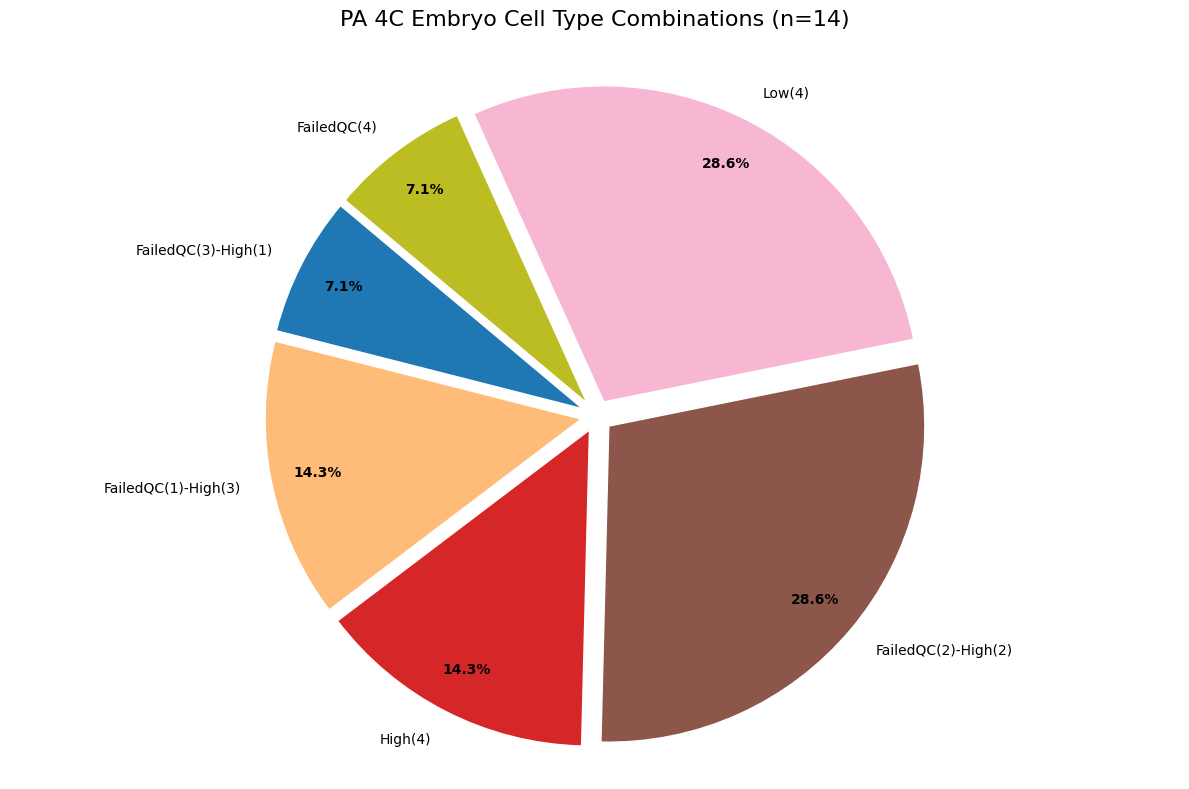

Processed 14 embryos. Output written to PA-4C-RNA-embryo_type_combinations.txt.
No embryos with both High and Low combinations found.


In [17]:
#PA 4C RNA
from collections import defaultdict, Counter
import matplotlib.pyplot as plt

input_file_name = "PA-4C-RNA-blastomere-type.txt"
output_file_name = "PA-4C-RNA-embryo_type_combinations.txt"

# 读取文件并解析数据
def read_and_parse(input_file_name):
    embryo_data = defaultdict(list)
    with open(input_file_name, 'r') as file:
        lines = file.readlines()
    
    for line in lines:
        parts = line.strip().split('\t')
        if len(parts) < 2:
            continue
        cell_id = parts[0].strip()
        cell_type = parts[1].strip().split('-')[2]  # Extract 'High', 'Low', or 'FailedQC'
        
        # Extract embryo prefix by joining all but the last part after splitting by '.'
        split_id = cell_id.split('.')
        if len(split_id) > 1:
            embryo_prefix = '.'.join(split_id[:-1])
            embryo_data[embryo_prefix].append(cell_type)
    
    return embryo_data

# 生成细胞类型组合字符串（按类型字母顺序排序以确保一致性）
def generate_combination_label(cell_types):
    type_count = Counter(cell_types)
    sorted_types = sorted(type_count.keys())  # Sort keys alphabetically for consistency
    combination = '-'.join([f"{t}({type_count[t]})" for t in sorted_types])
    return combination

# 统计胚胎的细胞类型组合（不修改原列表）
def count_combinations(embryo_data):
    combination_counts = Counter()
    total_embryos = len(embryo_data)
    
    for cell_types in embryo_data.values():
        # Create a copy to avoid modifying the original list
        temp_types = cell_types[:]
        # Pad with 'FailedQC' if fewer than 4 cells
        while len(temp_types) < 4:
            temp_types.append('FailedQC')
        # Generate combination label
        combination = generate_combination_label(temp_types)
        combination_counts[combination] += 1
    
    return combination_counts, total_embryos

# 计算百分比并写入文件
def write_output(embryo_data, combination_counts, total_embryos, output_file_name):
    with open(output_file_name, 'w') as output_file:
        # Write per-embryo details
        output_file.write("Per-Embryo Cell Type Combinations:\n")
        for embryo_id, cell_types in sorted(embryo_data.items()):  # Sort for consistent output
            temp_types = cell_types[:]
            while len(temp_types) < 4:
                temp_types.append('FailedQC')
            combination = generate_combination_label(temp_types)
            output_file.write(f"Embryo ID: {embryo_id}, Combination: {combination}\n")
        
        # Write summary
        output_file.write(f"\nSummary (Total Embryos: {total_embryos}):\n")
        for combination, count in sorted(combination_counts.items()):  # Sort for consistent output
            percentage = (count / total_embryos) * 100
            output_file.write(f"{combination}: {count} ({percentage:.2f}%)\n")
    
    return combination_counts

# 绘制饼图
def plot_pie_chart(combination_counts, total_embryos):
    if not combination_counts:
        print("No data to plot.")
        return
    
    labels = list(combination_counts.keys())
    sizes = list(combination_counts.values())
    cmap = plt.get_cmap('tab20')
    colors = [cmap(i / len(labels)) for i in range(len(labels))]

    plt.figure(figsize=(12, 8))
    explode = [0.05 if size / sum(sizes) > 0.05 else 0 for size in sizes]  # Slight explode for larger slices
    wedges, texts, autotexts = plt.pie(
        sizes, 
        labels=labels, 
        autopct='%1.1f%%', 
        startangle=140, 
        colors=colors, 
        explode=explode, 
        pctdistance=0.85, 
        textprops={'fontsize': 10},
        wedgeprops={'edgecolor': 'white', 'linewidth': 1}
    )
    # 设置特定标签的颜色和加粗
    for i, text in enumerate(texts):
        if "High" in labels[i] and "Low" in labels[i]:
            text.set_color('red')
            text.set_fontweight('bold')
            
    # Improve text readability
    for autotext in autotexts:
        autotext.set_color('black')
        autotext.set_fontweight('bold')

    plt.axis('equal')
    plt.title(f'PA 4C Embryo Cell Type Combinations (n={total_embryos})', fontsize=16, pad=20)
    plt.tight_layout()
    plt.show()

# 打印需要高亮的胚胎ID（即组合中同时包含High和Low的胚胎）
def print_highlighted_embryos(embryo_data):
    highlighted_embryos = []
    for embryo_id, cell_types in sorted(embryo_data.items()):
        temp_types = cell_types[:]
        while len(temp_types) < 4:
            temp_types.append('FailedQC')
        combination = generate_combination_label(temp_types)
        if "High" in combination and "Low" in combination:
            highlighted_embryos.append(embryo_id)
    
    if highlighted_embryos:
        print("Highlighted Embryo IDs (combinations with both High and Low):")
        for eid in highlighted_embryos:
            print(f"- {eid}")
    else:
        print("No embryos with both High and Low combinations found.")
    
    return highlighted_embryos

    
# 主函数
def main():
    embryo_data = read_and_parse(input_file_name)
    combination_counts, total_embryos = count_combinations(embryo_data)
    write_output(embryo_data, combination_counts, total_embryos, output_file_name)
    plot_pie_chart(combination_counts, total_embryos)
    print(f"Processed {total_embryos} embryos. Output written to {output_file_name}.")
    
    # 新增：打印高亮胚胎ID
    print_highlighted_embryos(embryo_data)

if __name__ == "__main__":
    main()

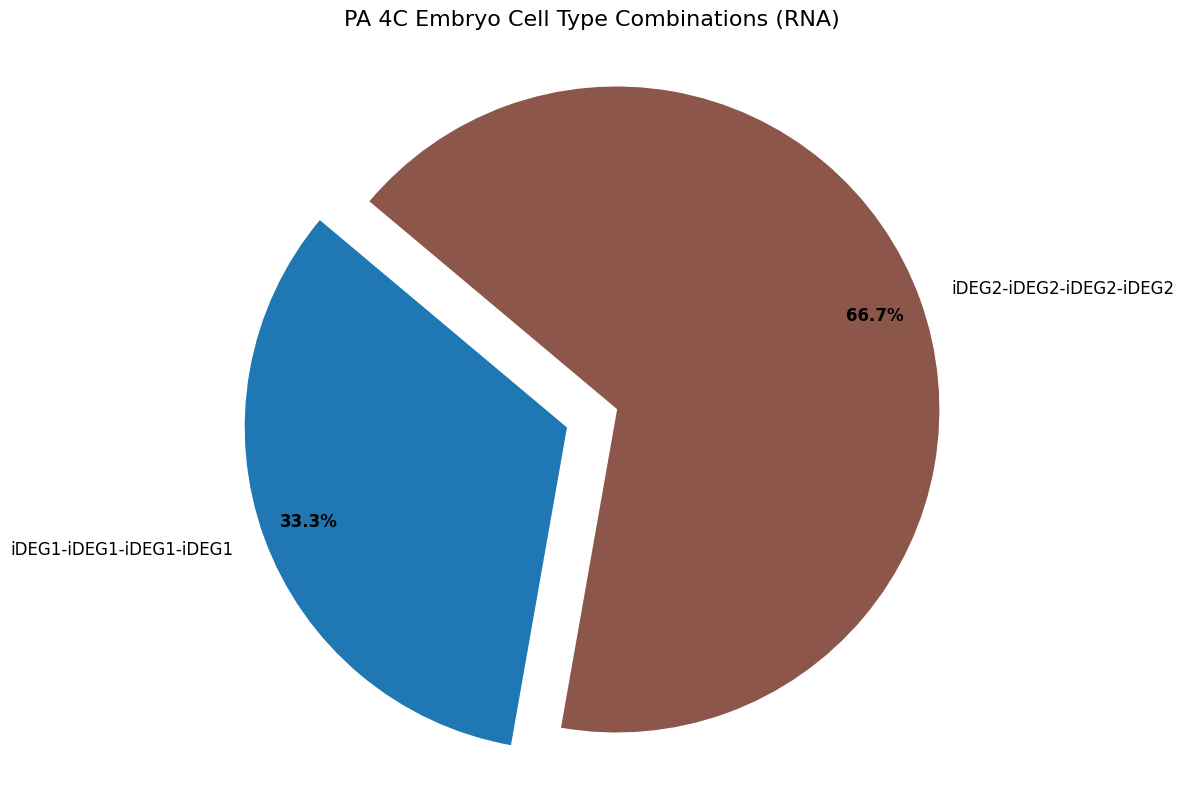

No embryos with both High and Low combinations found.
Processed 6 embryos. Output written to PA-4C-RNA-embryo_type_combinations.txt.


In [2]:
##PA 4C RNA 剔除未通过 QC 的胚胎
from collections import defaultdict, Counter
import matplotlib.pyplot as plt
from IPython.display import SVG, display

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

input_file_name = "PA-4C-RNA-blastomere-type_rmFailedQC.txt"
output_file_name = "PA-4C-RNA-embryo_type_combinations.txt"
EXPECTED_CELL_NUM = 4  # 4C 阶段

# =============================
# 读取文件并解析数据
# =============================
def read_and_parse(input_file_name):
    embryo_data = defaultdict(list)
    with open(input_file_name, 'r') as file:
        for line in file:
            parts = line.strip().split('\t')
            if len(parts) < 2:
                continue
            cell_id = parts[0].strip()
            cell_type = parts[1].strip().split('-')[-1]  # 'High' 或 'Low'

            # embryo ID = 前两段或前三段（根据你的数据格式）
            split_id = cell_id.split('.')
            if len(split_id) > 1:
                embryo_prefix = '.'.join(split_id[:-1])
                embryo_data[embryo_prefix].append(cell_type)

    return embryo_data

# =============================
# 生成组合字符串
# =============================
def generate_combination_label(cell_types):
    sorted_types = sorted(cell_types)
    combination = '-'.join(sorted_types)
    return combination

# =============================
# 严格 QC 筛选并统计组合
# =============================
def count_combinations(embryo_data):
    combination_counts = Counter()
    kept_embryos = 0
    filtered_embryo_data = dict()

    for embryo_id, cell_types in embryo_data.items():
        if len(cell_types) != EXPECTED_CELL_NUM:
            continue  # 严格剔除未通过 QC 的胚胎

        kept_embryos += 1
        combination = generate_combination_label(cell_types)
        combination_counts[combination] += 1
        filtered_embryo_data[embryo_id] = cell_types

    return filtered_embryo_data, combination_counts, kept_embryos

# =============================
# 输出文件
# =============================
def write_output(filtered_embryo_data, combination_counts, kept_embryos, output_file_name):
    with open(output_file_name, 'w') as out:
        out.write("Per-Embryo Cell Type Combinations (QC passed):\n")
        for embryo_id, cell_types in sorted(filtered_embryo_data.items()):
            combination = generate_combination_label(cell_types)
            out.write(f"{embryo_id}\t{combination}\n")

        out.write(f"\nSummary (Total embryos passed QC: {kept_embryos}):\n")
        for combination, count in sorted(combination_counts.items()):
            percentage = count / kept_embryos * 100
            out.write(f"{combination}: {count} ({percentage:.2f}%)\n")

# =============================
# 绘制饼图
# =============================
def plot_pie_chart(combination_counts, kept_embryos):
    if not combination_counts:
        print("No data to plot.")
        return

    labels = list(combination_counts.keys())
    sizes = list(combination_counts.values())
    cmap = plt.get_cmap('tab20')
    colors = [cmap(i / len(labels)) for i in range(len(labels))]

    plt.figure(figsize=(12, 8))
    explode = [0.08] * len(labels)

    wedges, texts, autotexts = plt.pie(
        sizes,
        labels=labels,
        autopct='%1.1f%%',
        startangle=140,
        colors=colors,
        explode=explode,
        pctdistance=0.85,
        textprops={'fontsize': 12},
        wedgeprops={'edgecolor': 'white', 'linewidth': 1}
    )

    # 高亮出现分化组合（同时包含 High 和 Low）
    for i, text in enumerate(texts):
        if "High" in labels[i] and "Low" in labels[i]:
            text.set_color('red')
            text.set_fontweight('bold')

    for autotext in autotexts:
        autotext.set_fontweight('bold')

    plt.axis('equal')
    plt.title(f"PA 4C Embryo Cell Type Combinations (RNA)", fontsize=16, pad=20)
    plt.tight_layout()
    plt.savefig('PA_4C_RNA_Cell_Type_Combinations.svg', dpi=300, bbox_inches='tight', transparent=True)
    plt.show()
    
    
# =============================
# 打印高亮胚胎 ID
# =============================
def print_highlighted_embryos(filtered_embryo_data):
    highlighted = []
    for embryo_id, cell_types in filtered_embryo_data.items():
        if "iDEG1" in cell_types and "iDEG2" in cell_types:
            highlighted.append(embryo_id)
    if highlighted:
        print("Highlighted Embryo IDs (both High and Low present):")
        for eid in highlighted:
            print(f"- {eid}")
    else:
        print("No embryos with both High and Low combinations found.")
    return highlighted

# =============================
# 主函数
# =============================
def main():
    embryo_data = read_and_parse(input_file_name)
    filtered_embryo_data, combination_counts, kept_embryos = count_combinations(embryo_data)
    write_output(filtered_embryo_data, combination_counts, kept_embryos, output_file_name)
    plot_pie_chart(combination_counts, kept_embryos)
    print_highlighted_embryos(filtered_embryo_data)
    print(f"Processed {kept_embryos} embryos. Output written to {output_file_name}.")

if __name__ == "__main__":
    main()


Number of complete embryos: 32

[RED LABEL EMBRYOS - ps1-ps2]
IVF-2-105
IVF-2-59

Total ps1-ps2 embryos: 2
Results saved to: IVF-2C_ps_clusters_embryo_type_combinations_complete_only.txt


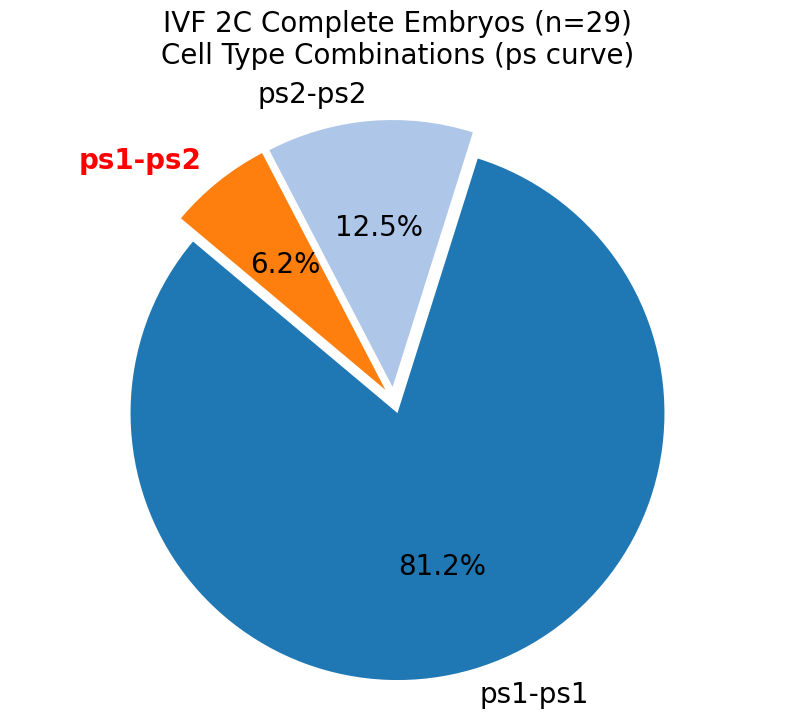

In [5]:
from collections import defaultdict, Counter
import matplotlib.pyplot as plt
from IPython.display import SVG, display

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

input_file_name = "IVF-2C_ps_clusters.txt"
output_file_name = "IVF-2C_ps_clusters_embryo_type_combinations_complete_only.txt"


# =========================
# 1. 读取并解析数据
# =========================
def read_and_parse(input_file_name):

    embryo_data = defaultdict(list)

    with open(input_file_name, 'r') as file:
        for line in file:
            parts = line.strip().split('\t')

            # 跳过header
            if parts[0] == "ID":
                continue

            if len(parts) < 2:
                continue

            embryo_id = '-'.join(parts[0].split('-')[:3])

            # =========================
            # ✔ 关键修改：解析 ps1 / ps2
            # =========================
            cell_type = parts[1].split('-')[-1]

            embryo_data[embryo_id].append(cell_type)

    return embryo_data


# =========================
# 2. 只保留完整胚胎
# =========================
def count_complete_embryos(embryo_data):

    embryo_type_count = Counter()
    filtered_embryos = {}

    # ⭐ 新增：记录组合对应的胚胎ID
    combination_to_embryos = defaultdict(list)

    for embryo_id, cell_types in embryo_data.items():

        if len(cell_types) != 2:
            continue

        if "Undefined" in cell_types:
            continue

        filtered_embryos[embryo_id] = cell_types

        sorted_types = sorted(cell_types)

        if sorted_types[0] == sorted_types[1]:
            combination = f"{sorted_types[0]}-{sorted_types[0]}"
        else:
            combination = '-'.join(sorted_types)

        embryo_type_count[combination] += 1

        # ⭐ 记录 embryo_id
        combination_to_embryos[combination].append(embryo_id)

    total_embryos = len(filtered_embryos)

    return filtered_embryos, embryo_type_count, total_embryos, combination_to_embryos


# =========================
# 3. 写入结果文件
# =========================
def write_results(embryo_data, combination_counts, total_embryos, output_file_name):

    with open(output_file_name, 'w') as output_file:

        output_file.write("Complete embryos only (2 blastomeres, both passed QC)\n\n")

        for embryo_id, cell_types in embryo_data.items():

            sorted_types = sorted(cell_types)

            if sorted_types[0] == sorted_types[1]:
                combination = f"{sorted_types[0]}-{sorted_types[0]}"
            else:
                combination = '-'.join(sorted_types)

            output_file.write(f"{embryo_id}\t{combination}\n")

        output_file.write("\nType Combinations and Percentages:\n")

        for combination, count in combination_counts.items():
            percentage = (count / total_embryos) * 100
            output_file.write(f"{combination}: {count} ({percentage:.2f}%)\n")

    print("Results saved to:", output_file_name)


# =========================
# 4. 绘图
# =========================
def plot_pie_chart(combination_counts, total_embryos):

    labels = list(combination_counts.keys())
    sizes = list(combination_counts.values())

    cmap = plt.get_cmap('tab20')
    colors = [cmap(i) for i in range(len(labels))]

    plt.figure(figsize=(10, 8))

    explode = [0.05] * len(labels)

    wedges, texts, autotexts = plt.pie(
        sizes,
        labels=labels,
        autopct='%1.1f%%',
        startangle=140,
        colors=colors,
        explode=explode,
        textprops={'fontsize': 20}
    )

    # =========================
    # ✔ 只修改文字颜色
    # =========================
    for i, text in enumerate(texts):
        if labels[i] == "ps1-ps2":
            text.set_color('red')
            text.set_fontweight('bold')

    plt.axis('equal')

    plt.title(
        f'IVF 2C Complete Embryos (n=29)\nCell Type Combinations (ps curve)',
        fontsize=20,
        pad=20
    )
    plt.savefig('IVF_2C_embryo_type_count_ps.svg', dpi=300, bbox_inches='tight', transparent=True)
    plt.show()


# =========================
# 5. 主函数
# =========================
def main():

    embryo_data = read_and_parse(input_file_name)

    filtered_embryos, combination_counts, total_embryos, combination_to_embryos = \
        count_complete_embryos(embryo_data)

    print("Number of complete embryos:", total_embryos)

    # =========================
    # ⭐ 打印标红胚胎 ID
    # =========================
    target_combo = "ps1-ps2"

    if target_combo in combination_to_embryos:

        print("\n[RED LABEL EMBRYOS - ps1-ps2]")
        for eid in combination_to_embryos[target_combo]:
            print(eid)

        print(f"\nTotal ps1-ps2 embryos: {len(combination_to_embryos[target_combo])}")
    else:
        print("\nNo ps1-ps2 embryos found")

    write_results(
        filtered_embryos,
        combination_counts,
        total_embryos,
        output_file_name
    )

    plot_pie_chart(combination_counts, total_embryos)


if __name__ == "__main__":
    main()

Complete embryos: 15

[RED EMBRYOS: ps1 & ps2 both present]

IVF-4-99
IVF-4-89
IVF-4-84
IVF-4-18
IVF-4-54

Total red embryos: 5
Saved: IVF-4C_ps_counts_complete_only.txt


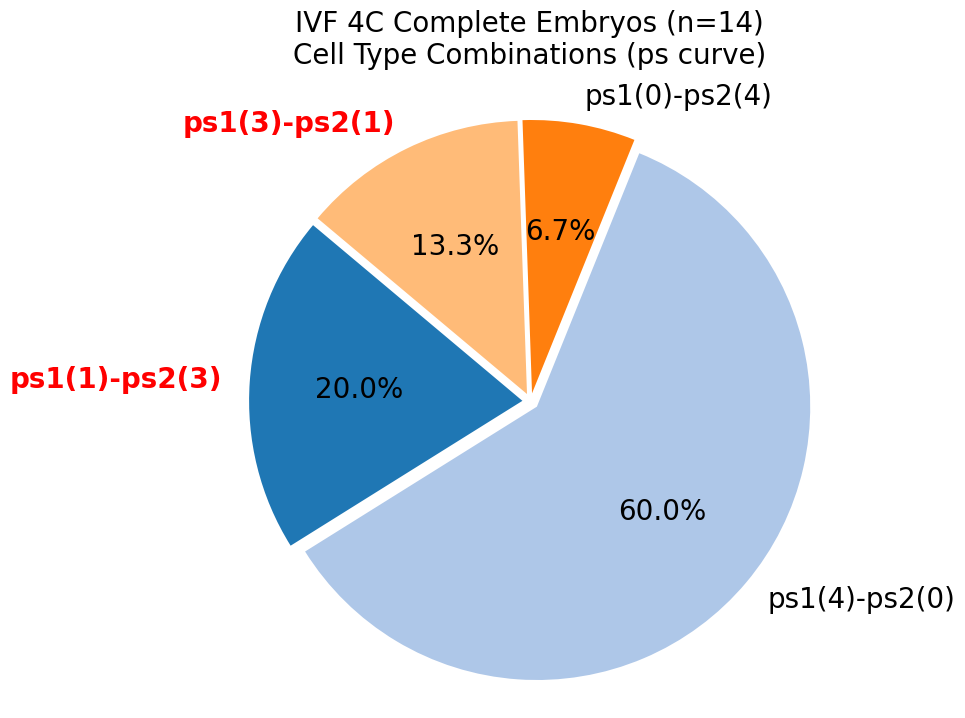

In [6]:
from collections import defaultdict, Counter
import matplotlib.pyplot as plt
from IPython.display import SVG, display

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

input_file_name = "IVF-4C_ps_clusters.txt"
output_file_name = "IVF-4C_ps_counts_complete_only.txt"


# =========================
# 1. 读取数据
# =========================
def read_and_parse(input_file_name):

    embryo_data = defaultdict(list)

    with open(input_file_name, 'r') as file:
        for line in file:
            parts = line.strip().split('\t')

            if parts[0] == "ID":
                continue

            if len(parts) < 2:
                continue

            embryo_id = '-'.join(parts[0].split('-')[:3])

            # ✔ ps1 / ps2 / Undefined
            cell_type = parts[1].split('-')[-1]

            embryo_data[embryo_id].append(cell_type)

    return embryo_data


# =========================
# 2. 只保留完整 4C
# =========================
def filter_embryos(embryo_data):

    filtered = {}
    counts = Counter()

    # ⭐ 新增：记录组合 → embryo_id
    combo_to_embryos = defaultdict(list)

    for eid, types in embryo_data.items():

        if len(types) != 4:
            continue

        if "Undefined" in types:
            continue

        filtered[eid] = types

        c = Counter(types)

        ps1 = c.get("ps1", 0)
        ps2 = c.get("ps2", 0)

        label = f"ps1({ps1})-ps2({ps2})"

        counts[label] += 1

        # ⭐ 记录
        combo_to_embryos[label].append(eid)

    return filtered, counts, len(filtered), combo_to_embryos


# =========================
# 3. 输出文件
# =========================
def write_results(filtered, counts, total, out_file):

    with open(out_file, 'w') as f:

        f.write("IVF 4C embryos (ps counts only)\n\n")

        for eid, types in filtered.items():

            c = Counter(types)
            ps1 = c.get("ps1", 0)
            ps2 = c.get("ps2", 0)

            f.write(f"{eid}\tps1({ps1})-ps2({ps2})\n")

        f.write("\nSummary:\n")

        for k, v in counts.items():
            f.write(f"{k}: {v} ({v/total*100:.2f}%)\n")

    print("Saved:", out_file)


# =========================
# 4. 饼图
# =========================
def plot_pie(counts, total):

    labels = list(counts.keys())
    sizes = list(counts.values())

    cmap = plt.get_cmap('tab20')
    colors = [cmap(i) for i in range(len(labels))]

    plt.figure(figsize=(10, 8))

    explode = [0.03] * len(labels)

    wedges, texts, autotexts = plt.pie(
        sizes,
        labels=labels,
        autopct='%1.1f%%',
        startangle=140,
        colors=colors,
        explode=explode,
        textprops={'fontsize': 20}
    )


    # =========================
    # ✔ 只要同时存在 ps1 + ps2 就标红
    # =========================
    for i, text in enumerate(texts):

        label = labels[i]

        try:
            part1, part2 = label.split('-')

            ps1 = int(part1.split('(')[1].split(')')[0])
            ps2 = int(part2.split('(')[1].split(')')[0])

            # ✔ 关键逻辑
            if ps1 > 0 and ps2 > 0:
                text.set_color('red')
                text.set_fontweight('bold')

        except:
            continue

    plt.axis('equal')

    plt.title(f"IVF 4C Complete Embryos (n=14)\nCell Type Combinations (ps curve)", fontsize=20,pad=20)
    plt.savefig('IVF_4C_embryo_type_count_ps.svg', dpi=300, bbox_inches='tight', transparent=True)
    plt.show()


# =========================
# 5. main
# =========================
def main():

    data = read_and_parse(input_file_name)

    filtered, counts, total, combo_to_embryos = filter_embryos(data)

    print("Complete embryos:", total)

    # =========================
    # ⭐ 标红逻辑：ps1 > 0 AND ps2 > 0
    # =========================
    print("\n[RED EMBRYOS: ps1 & ps2 both present]\n")

    red_embryos = []

    for label, eids in combo_to_embryos.items():

        try:
            part1, part2 = label.split('-')

            ps1 = int(part1.split('(')[1].split(')')[0])
            ps2 = int(part2.split('(')[1].split(')')[0])

            if ps1 > 0 and ps2 > 0:
                red_embryos.extend(eids)

        except:
            continue

    for eid in red_embryos:
        print(eid)

    print(f"\nTotal red embryos: {len(red_embryos)}")

    write_results(filtered, counts, total, output_file_name)

    plot_pie(counts, total)


if __name__ == "__main__":
    main()

complete embryos: 22


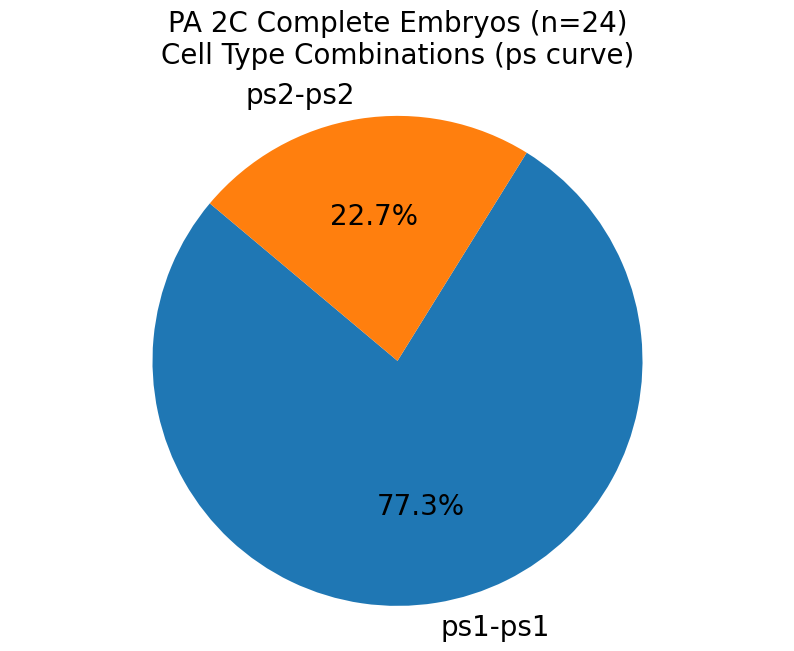

In [49]:
from collections import defaultdict, Counter
import matplotlib.pyplot as plt

input_file_name = "PA-2C_ps_clusters.txt"
output_file_name = "PA-2C_ps_embryo_type_combinations_complete_only.txt"


# =========================
# 1. 读取并解析（已修复）
# =========================
def read_and_parse(input_file_name):

    embryo_data = defaultdict(list)

    with open(input_file_name, 'r') as file:
        for line in file:

            parts = line.strip().split('\t')

            # ❗必须至少两列
            if len(parts) < 2:
                continue

            # 跳过header
            if parts[0] == "ID":
                continue

            # embryo ID（前2段）
            embryo_id_parts = parts[0].split('-')
            if len(embryo_id_parts) < 2:
                continue

            embryo_id = '-'.join(embryo_id_parts[:2])

            # =========================
            # ❗安全解析 cell_type
            # =========================
            ct_parts = parts[1].split('-')

            if len(ct_parts) < 3:
                continue

            cell_type = ct_parts[-1]   # ✔ 永远取最后一段 ps1/ps2

            embryo_data[embryo_id].append(cell_type)

    return embryo_data


# =========================
# 2. 过滤完整胚胎
# =========================
def count_complete_embryos(embryo_data):

    embryo_type_count = Counter()
    filtered_embryos = {}

    for embryo_id, cell_types in embryo_data.items():

        # 必须2个细胞
        if len(cell_types) != 2:
            continue

        # 剔除异常
        if "FailedQC" in cell_types or "Undefined" in cell_types:
            continue

        filtered_embryos[embryo_id] = cell_types

        sorted_types = sorted(cell_types)

        if sorted_types[0] == sorted_types[1]:
            combination = f"{sorted_types[0]}-{sorted_types[0]}"
        else:
            combination = '-'.join(sorted_types)

        embryo_type_count[combination] += 1

    total_embryos = len(filtered_embryos)

    return filtered_embryos, embryo_type_count, total_embryos


# =========================
# 3. 输出
# =========================
def write_results(embryo_data, combination_counts, total_embryos, output_file_name):

    with open(output_file_name, 'w') as f:

        f.write("PA-2C embryo ps combination\n\n")

        for embryo_id, cell_types in embryo_data.items():

            sorted_types = sorted(cell_types)

            if sorted_types[0] == sorted_types[1]:
                comb = f"{sorted_types[0]}-{sorted_types[0]}"
            else:
                comb = '-'.join(sorted_types)

            f.write(f"{embryo_id}\t{comb}\n")

        f.write("\nSummary:\n")

        for k, v in combination_counts.items():
            f.write(f"{k}: {v} ({v/total_embryos*100:.2f}%)\n")


# =========================
# 4. 饼图（红色标 ps1+ps2）
# =========================
def plot_pie_chart(combination_counts, total_embryos):

    labels = list(combination_counts.keys())
    sizes = list(combination_counts.values())

    plt.figure(figsize=(10, 7))

    wedges, texts, autotexts = plt.pie(
        sizes,
        labels=labels,
        autopct='%1.1f%%',
        startangle=140,
        textprops={'fontsize': 20}
    )

    for i, text in enumerate(texts):
        if "ps1" in labels[i] and "ps2" in labels[i]:
            text.set_color("red")
            text.set_fontweight("bold")

    plt.axis('equal')
    plt.title(f"PA 2C Complete Embryos (n=24)\nCell Type Combinations (ps curve)", fontsize=20,pad=20)
    
    plt.show()


# =========================
# 5. 主函数
# =========================
def main():

    embryo_data = read_and_parse(input_file_name)

    filtered, counts, total = count_complete_embryos(embryo_data)

    print("complete embryos:", total)

    write_results(filtered, counts, total, output_file_name)

    plot_pie_chart(counts, total)


if __name__ == "__main__":
    main()

complete embryos: 7

[RED EMBRYOS: contain both ps1 and ps2]

4-192
4-195
4-281

Total red embryos: 3


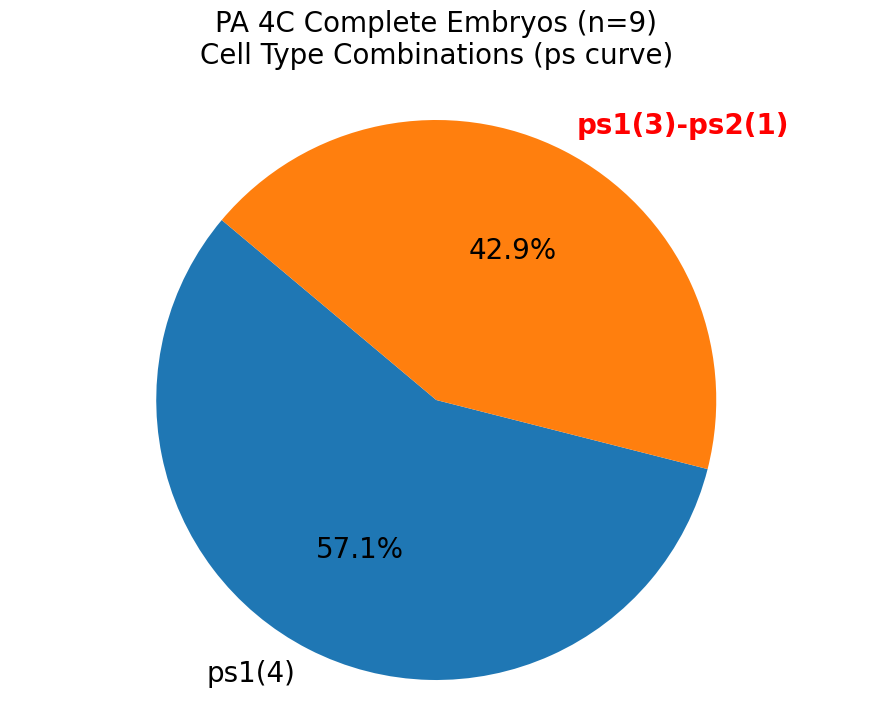

In [50]:
from collections import defaultdict, Counter
import matplotlib.pyplot as plt

input_file_name = "PA-4C_ps_clusters.txt"
output_file_name = "PA-4C_ps_embryo_type_combinations_complete_only.txt"


# =========================
# 1. 读取并解析（安全版）
# =========================
def read_and_parse(input_file_name):

    embryo_data = defaultdict(list)

    with open(input_file_name, 'r') as file:
        for line in file:

            parts = line.strip().split('\t')

            if len(parts) < 2:
                continue

            if parts[0] == "ID":
                continue

            # embryo ID（前2段）
            id_parts = parts[0].split('-')
            if len(id_parts) < 2:
                continue

            embryo_id = '-'.join(id_parts[:2])

            # 安全解析 cell type
            ct_parts = parts[1].split('-')
            if len(ct_parts) < 3:
                continue

            cell_type = ct_parts[-1]

            embryo_data[embryo_id].append(cell_type)

    return embryo_data


# =========================
# 2. 过滤完整4C胚胎
# =========================
def count_complete_embryos(embryo_data):

    embryo_type_count = Counter()
    filtered_embryos = {}

    # ⭐ 新增：组合 -> embryo_id
    combination_to_embryos = defaultdict(list)

    for embryo_id, cell_types in embryo_data.items():

        if len(cell_types) != 4:
            continue

        if "FailedQC" in cell_types or "Undefined" in cell_types:
            continue

        filtered_embryos[embryo_id] = cell_types

        type_count = Counter(cell_types)

        sorted_types = sorted(type_count.items())
        combination = '-'.join([f"{t}({c})" for t, c in sorted_types])

        embryo_type_count[combination] += 1

        # ⭐ 记录映射
        combination_to_embryos[combination].append(embryo_id)

    total_embryos = len(filtered_embryos)

    return filtered_embryos, embryo_type_count, total_embryos, combination_to_embryos


# =========================
# 3. 输出结果
# =========================
def write_results(embryo_data, combination_counts, total_embryos, output_file_name):

    with open(output_file_name, 'w') as f:

        f.write("PA-4C embryo ps composition\n\n")

        for embryo_id, cell_types in embryo_data.items():

            type_count = Counter(cell_types)
            sorted_types = sorted(type_count.items())

            comb = '-'.join([f"{t}({c})" for t, c in sorted_types])

            f.write(f"{embryo_id}\t{comb}\n")

        f.write("\nSummary:\n")

        for k, v in combination_counts.items():
            f.write(f"{k}: {v} ({v/total_embryos*100:.2f}%)\n")


# =========================
# 4. 饼图（ps1+ps2标红）
# =========================
def plot_pie_chart(combination_counts, total_embryos):

    labels = list(combination_counts.keys())
    sizes = list(combination_counts.values())

    plt.figure(figsize=(11, 8))

    wedges, texts, autotexts = plt.pie(
        sizes,
        labels=labels,
        autopct='%1.1f%%',
        startangle=140,
        textprops={'fontsize': 20}
    )

    # 🔴 只要同时含 ps1 + ps2 就标红
    for i, text in enumerate(texts):
        if ("ps1" in labels[i]) and ("ps2" in labels[i]):
            text.set_color("red")
            text.set_fontweight("bold")

    plt.axis('equal')
    plt.title(f"PA 4C Complete Embryos (n=9)\nCell Type Combinations (ps curve)", fontsize=20,pad=20)
    plt.show()


# =========================
# 5. 主函数
# =========================
def main():

    embryo_data = read_and_parse(input_file_name)

    filtered, counts, total, combo_to_embryos = count_complete_embryos(embryo_data)

    print("complete embryos:", total)

    # =========================
    # 🔴 打印 ps1 + ps2 胚胎
    # =========================
    print("\n[RED EMBRYOS: contain both ps1 and ps2]\n")

    red_list = []

    for combo, eids in combo_to_embryos.items():

        # 只要组合字符串同时包含 ps1 和 ps2
        if ("ps1" in combo) and ("ps2" in combo):
            red_list.extend(eids)

    for eid in red_list:
        print(eid)

    print(f"\nTotal red embryos: {len(red_list)}")

    write_results(filtered, counts, total, output_file_name)

    plot_pie_chart(counts, total)


if __name__ == "__main__":
    main()

In [26]:
cd /home/lihaoxing/jupyter

/home/lihaoxing/jupyter


Number of complete embryos: 32
Results saved to: IVF_2C_AB_clustering_embryo_type_combinations_complete_only.txt


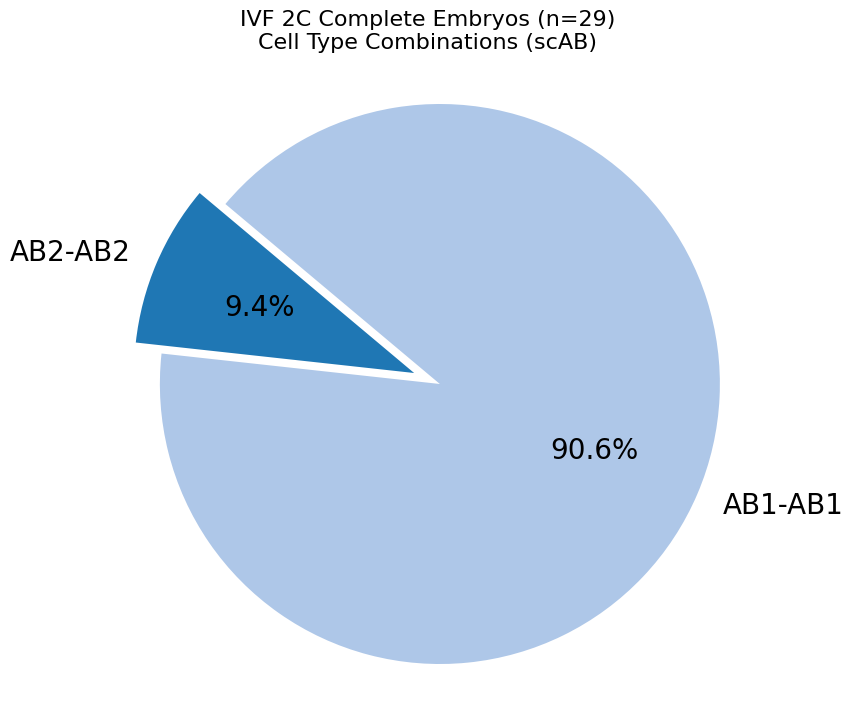

In [7]:
from collections import defaultdict, Counter
import matplotlib.pyplot as plt
from IPython.display import SVG, display

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

input_file_name = "IVF_2C_AB_clustering.tsv"
output_file_name = "IVF_2C_AB_clustering_embryo_type_combinations_complete_only.txt"


# =========================
# 1. 读取并解析数据
# =========================
def read_and_parse(input_file_name):

    embryo_data = defaultdict(list)

    with open(input_file_name, 'r') as file:
        for line in file:
            parts = line.strip().split('\t')

            # 跳过header
            if parts[0] == "ID":
                continue

            if len(parts) < 2:
                continue

            embryo_id = '-'.join(parts[0].split('-')[:3])

            # =========================
            # ✔ 关键修改：解析 ps1 / ps2
            # =========================
            cell_type = parts[1].split('-')[-1]

            embryo_data[embryo_id].append(cell_type)

    return embryo_data


# =========================
# 2. 只保留完整胚胎
# =========================
def count_complete_embryos(embryo_data):

    embryo_type_count = Counter()
    filtered_embryos = {}

    for embryo_id, cell_types in embryo_data.items():

        # 必须恰好两个细胞
        if len(cell_types) != 2:
            continue

        # 剔除 Undefined
        if "Undefined" in cell_types:
            continue

        filtered_embryos[embryo_id] = cell_types

        sorted_types = sorted(cell_types)

        if sorted_types[0] == sorted_types[1]:
            combination = f"{sorted_types[0]}-{sorted_types[0]}"
        else:
            combination = '-'.join(sorted_types)

        embryo_type_count[combination] += 1

    total_embryos = len(filtered_embryos)

    return filtered_embryos, embryo_type_count, total_embryos


# =========================
# 3. 写入结果文件
# =========================
def write_results(embryo_data, combination_counts, total_embryos, output_file_name):

    with open(output_file_name, 'w') as output_file:

        output_file.write("Complete embryos only (2 blastomeres, both passed QC)\n\n")

        for embryo_id, cell_types in embryo_data.items():

            sorted_types = sorted(cell_types)

            if sorted_types[0] == sorted_types[1]:
                combination = f"{sorted_types[0]}-{sorted_types[0]}"
            else:
                combination = '-'.join(sorted_types)

            output_file.write(f"{embryo_id}\t{combination}\n")

        output_file.write("\nType Combinations and Percentages:\n")

        for combination, count in combination_counts.items():
            percentage = (count / total_embryos) * 100
            output_file.write(f"{combination}: {count} ({percentage:.2f}%)\n")

    print("Results saved to:", output_file_name)


# =========================
# 4. 绘图
# =========================
def plot_pie_chart(combination_counts, total_embryos):

    labels = list(combination_counts.keys())
    sizes = list(combination_counts.values())

    cmap = plt.get_cmap('tab20')
    colors = [cmap(i) for i in range(len(labels))]

    plt.figure(figsize=(10, 8))

    explode = [0.05] * len(labels)

    wedges, texts, autotexts = plt.pie(
        sizes,
        labels=labels,
        autopct='%1.1f%%',
        startangle=140,
        colors=colors,
        explode=explode,
        textprops={'fontsize': 20}
    )

    # =========================
    # ✔ 只修改文字颜色
    # =========================
    for i, text in enumerate(texts):
        if labels[i] == "AB1-AB2":
            text.set_color('red')
            text.set_fontweight('bold')

    plt.axis('equal')

    plt.title(
        f'IVF 2C Complete Embryos (n=29)\nCell Type Combinations (scAB)',
        fontsize=16,
        pad=20
    )
    plt.savefig('IVF_2C_embryo_type_count_ab.svg', dpi=300, bbox_inches='tight', transparent=True)
    plt.show()


# =========================
# 5. 主函数
# =========================
def main():

    embryo_data = read_and_parse(input_file_name)

    filtered_embryos, combination_counts, total_embryos = \
        count_complete_embryos(embryo_data)

    print("Number of complete embryos:", total_embryos)

    write_results(
        filtered_embryos,
        combination_counts,
        total_embryos,
        output_file_name
    )

    plot_pie_chart(combination_counts, total_embryos)


if __name__ == "__main__":
    main()

Complete embryos: 15
Saved: IVF_4C_AB_clustering_counts_complete_only.txt


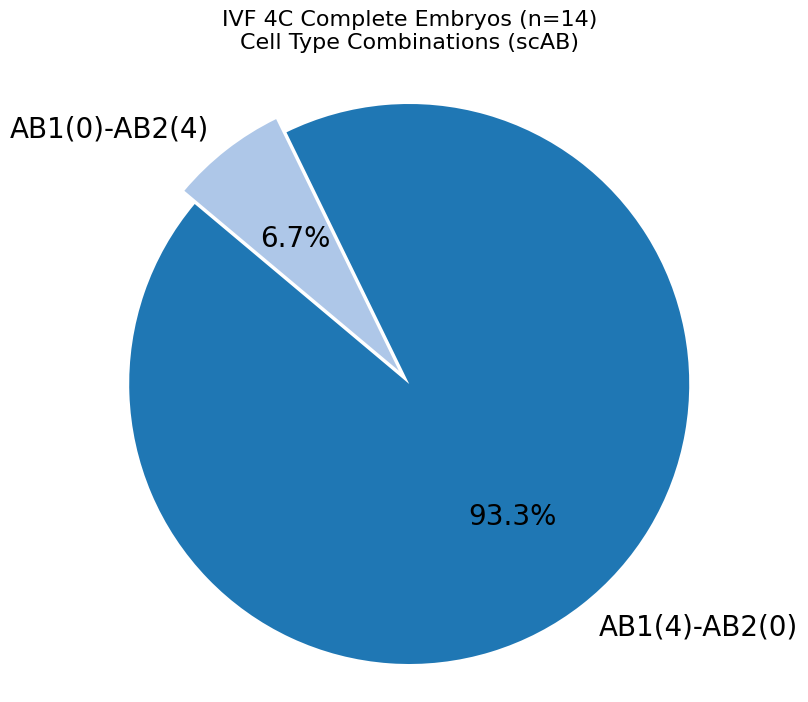

In [8]:
from collections import defaultdict, Counter
import matplotlib.pyplot as plt
from IPython.display import SVG, display

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

input_file_name = "IVF_4C_AB_clustering.tsv"
output_file_name = "IVF_4C_AB_clustering_counts_complete_only.txt"


# =========================
# 1. 读取数据
# =========================
def read_and_parse(input_file_name):

    embryo_data = defaultdict(list)

    with open(input_file_name, 'r') as file:
        for line in file:
            parts = line.strip().split('\t')

            if parts[0] == "ID":
                continue

            if len(parts) < 2:
                continue

            embryo_id = '-'.join(parts[0].split('-')[:3])

            # ✔ ps1 / ps2 / Undefined
            cell_type = parts[1].split('-')[-1]

            embryo_data[embryo_id].append(cell_type)

    return embryo_data


# =========================
# 2. 只保留完整 4C
# =========================
def filter_embryos(embryo_data):

    filtered = {}
    counts = Counter()

    for eid, types in embryo_data.items():

        if len(types) != 4:
            continue

        if "Undefined" in types:
            continue

        filtered[eid] = types

        c = Counter(types)

        ps1 = c.get("AB1", 0)
        ps2 = c.get("AB2", 0)

        label = f"AB1({ps1})-AB2({ps2})"

        counts[label] += 1

    return filtered, counts, len(filtered)


# =========================
# 3. 输出文件
# =========================
def write_results(filtered, counts, total, out_file):

    with open(out_file, 'w') as f:

        f.write("IVF 4C embryos (ps counts only)\n\n")

        for eid, types in filtered.items():

            c = Counter(types)
            ps1 = c.get("AB1", 0)
            ps2 = c.get("AB2", 0)

            f.write(f"{eid}\tAB1({ps1})-AB2({ps2})\n")

        f.write("\nSummary:\n")

        for k, v in counts.items():
            f.write(f"{k}: {v} ({v/total*100:.2f}%)\n")

    print("Saved:", out_file)


# =========================
# 4. 饼图
# =========================
def plot_pie(counts, total):

    labels = list(counts.keys())
    sizes = list(counts.values())

    cmap = plt.get_cmap('tab20')
    colors = [cmap(i) for i in range(len(labels))]

    plt.figure(figsize=(10, 8))

    explode = [0.03] * len(labels)

    wedges, texts, autotexts = plt.pie(
        sizes,
        labels=labels,
        autopct='%1.1f%%',
        startangle=140,
        colors=colors,
        explode=explode,
        textprops={'fontsize': 20}
    )


    # =========================
    # ✔ 只要同时存在 ps1 + ps2 就标红
    # =========================
    for i, text in enumerate(texts):

        label = labels[i]

        try:
            part1, part2 = label.split('-')

            ps1 = int(part1.split('(')[1].split(')')[0])
            ps2 = int(part2.split('(')[1].split(')')[0])

            # ✔ 关键逻辑
            if ps1 > 0 and ps2 > 0:
                text.set_color('red')
                text.set_fontweight('bold')

        except:
            continue

    plt.axis('equal')

    plt.title(f"IVF 4C Complete Embryos (n=14)\nCell Type Combinations (scAB)", fontsize=16,pad=20)
    plt.savefig('IVF_4C_embryo_type_count_ab.svg', dpi=300, bbox_inches='tight', transparent=True)
    plt.show()


# =========================
# 5. main
# =========================
def main():

    data = read_and_parse(input_file_name)

    filtered, counts, total = filter_embryos(data)

    print("Complete embryos:", total)

    write_results(filtered, counts, total, output_file_name)

    plot_pie(counts, total)


if __name__ == "__main__":
    main()

Number of complete embryos: 31

🔥 embryos with BOTH contact1 & contact2:
IVF-2-106
IVF-2-137
IVF-2-153
IVF-2-54
IVF-2-59
IVF-2-8
Results saved to: IVF_2C_contact_clustering_embryo_type_combinations_complete_only.txt


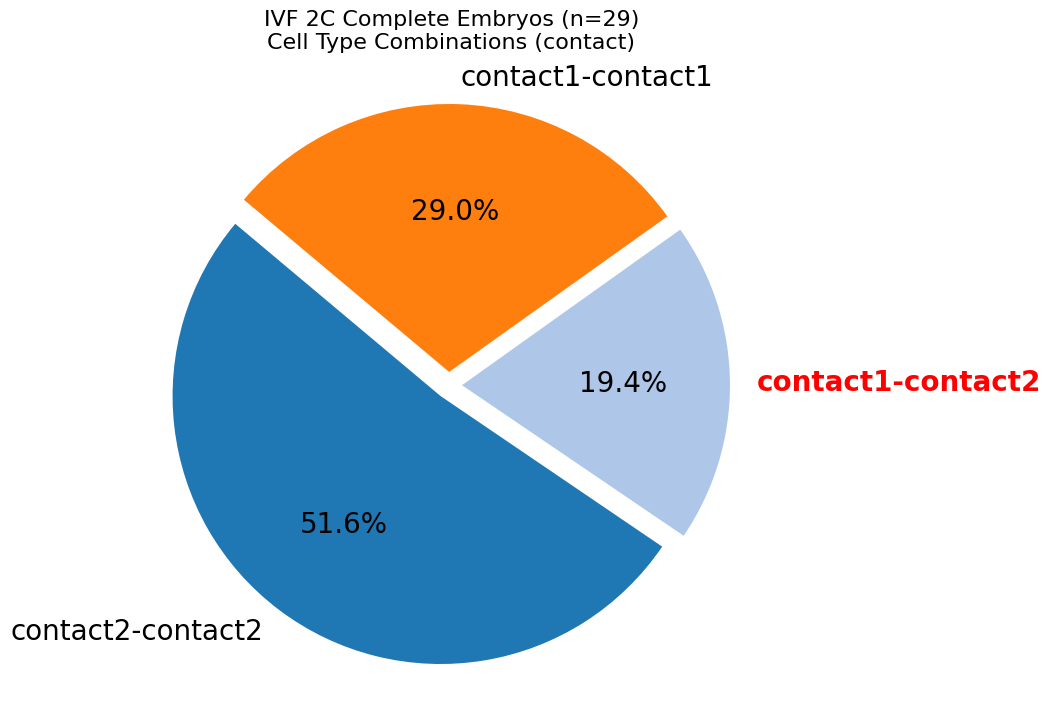

In [62]:
from collections import defaultdict, Counter
import matplotlib.pyplot as plt

input_file_name = "IVF_2C_2cluster_category.txt"
output_file_name = "IVF_2C_contact_clustering_embryo_type_combinations_complete_only.txt"


# =========================
# 1. 读取并解析数据
# =========================
def read_and_parse(input_file_name):

    embryo_data = defaultdict(list)

    with open(input_file_name, 'r') as file:
        for line in file:
            parts = line.strip().split('\t')

            # 跳过header
            if parts[0] == "ID":
                continue

            if len(parts) < 2:
                continue

            embryo_id = '-'.join(parts[0].split('-')[:3])

            # =========================
            # ✔ 关键修改：解析 ps1 / ps2
            # =========================
            cell_type = parts[1].split('-')[-1]

            embryo_data[embryo_id].append(cell_type)

    return embryo_data


# =========================
# 2. 只保留完整胚胎
# =========================
def count_complete_embryos(embryo_data):

    embryo_type_count = Counter()
    filtered_embryos = {}
    mixed_ids = []   # ✔ 新增：记录 contact1 + contact2 同时存在

    for embryo_id, cell_types in embryo_data.items():

        if len(cell_types) != 2:
            continue

        if "Undefined" in cell_types:
            continue

        filtered_embryos[embryo_id] = cell_types

        sorted_types = sorted(cell_types)

        if sorted_types[0] == sorted_types[1]:
            combination = f"{sorted_types[0]}-{sorted_types[0]}"
        else:
            combination = '-'.join(sorted_types)

        embryo_type_count[combination] += 1

        # =========================
        # ✔ 标红逻辑（关键）
        # =========================
        if "contact1" in cell_types and "contact2" in cell_types:
            mixed_ids.append(embryo_id)

    total_embryos = len(filtered_embryos)

    return filtered_embryos, embryo_type_count, total_embryos, mixed_ids


# =========================
# 3. 写入结果文件
# =========================
def write_results(embryo_data, combination_counts, total_embryos, output_file_name):

    with open(output_file_name, 'w') as output_file:

        output_file.write("Complete embryos only (2 blastomeres, both passed QC)\n\n")

        for embryo_id, cell_types in embryo_data.items():

            sorted_types = sorted(cell_types)

            if sorted_types[0] == sorted_types[1]:
                combination = f"{sorted_types[0]}-{sorted_types[0]}"
            else:
                combination = '-'.join(sorted_types)

            output_file.write(f"{embryo_id}\t{combination}\n")

        output_file.write("\nType Combinations and Percentages:\n")

        for combination, count in combination_counts.items():
            percentage = (count / total_embryos) * 100
            output_file.write(f"{combination}: {count} ({percentage:.2f}%)\n")

    print("Results saved to:", output_file_name)


# =========================
# 4. 绘图
# =========================
def plot_pie_chart(combination_counts, total_embryos):

    labels = list(combination_counts.keys())
    sizes = list(combination_counts.values())

    cmap = plt.get_cmap('tab20')
    colors = [cmap(i) for i in range(len(labels))]

    plt.figure(figsize=(10, 8))

    explode = [0.05] * len(labels)

    wedges, texts, autotexts = plt.pie(
        sizes,
        labels=labels,
        autopct='%1.1f%%',
        startangle=140,
        colors=colors,
        explode=explode,
        textprops={'fontsize': 20}
    )

    # =========================
    # ✔ 只修改文字颜色
    # =========================
    for i, text in enumerate(texts):
        if labels[i] == "contact1-contact2":
            text.set_color('red')
            text.set_fontweight('bold')

    plt.axis('equal')

    plt.title(
        f'IVF 2C Complete Embryos (n=29)\nCell Type Combinations (contact)',
        fontsize=16,
        pad=20
    )

    plt.show()


# =========================
# 5. 主函数
# =========================
def main():

    embryo_data = read_and_parse(input_file_name)

    filtered_embryos, combination_counts, total_embryos, mixed_ids = \
    count_complete_embryos(embryo_data)
    
    print("Number of complete embryos:", total_embryos)
    
    print("\n🔥 embryos with BOTH contact1 & contact2:")
    for eid in mixed_ids:
        print(eid)
        
    write_results(
        filtered_embryos,
        combination_counts,
        total_embryos,
        output_file_name
    )

    plot_pie_chart(combination_counts, total_embryos)


if __name__ == "__main__":
    main()

Complete embryos: 14

🔥 embryos with BOTH contact1 & contact2:
IVF-4-31
IVF-4-48
IVF-4-72
IVF-4-89
IVF-4-91
Saved: IVF_4C_contact_clustering_counts_complete_only.txt


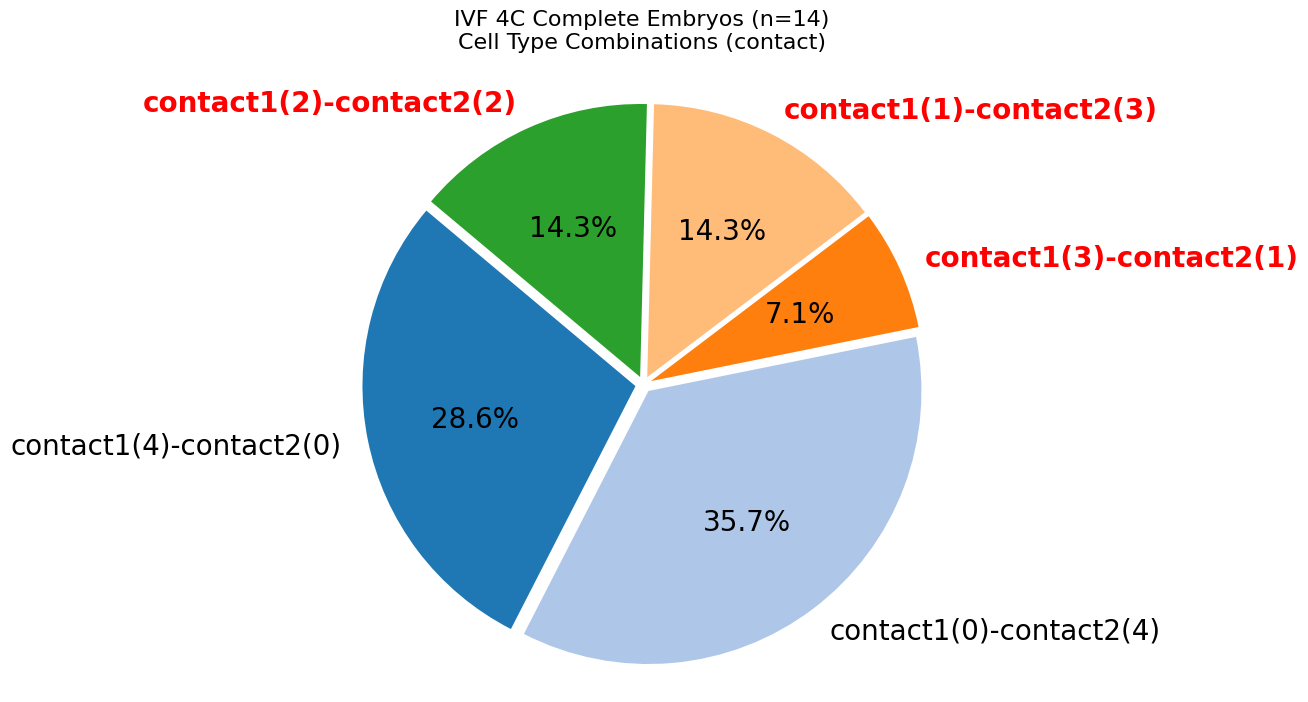

In [61]:
from collections import defaultdict, Counter
import matplotlib.pyplot as plt

input_file_name = "IVF_4C_2cluster_category.txt"
output_file_name = "IVF_4C_contact_clustering_counts_complete_only.txt"


# =========================
# 1. 读取数据
# =========================
def read_and_parse(input_file_name):

    embryo_data = defaultdict(list)

    with open(input_file_name, 'r') as file:
        for line in file:
            parts = line.strip().split('\t')

            if parts[0] == "ID":
                continue

            if len(parts) < 2:
                continue

            embryo_id = '-'.join(parts[0].split('-')[:3])

            # ✔ ps1 / ps2 / Undefined
            cell_type = parts[1].split('-')[-1]

            embryo_data[embryo_id].append(cell_type)

    return embryo_data


# =========================
# 2. 只保留完整 4C
# =========================
def filter_embryos(embryo_data):

    filtered = {}
    counts = Counter()
    mixed_ids = []   # ✔ 新增：记录 ps1 + ps2 同时存在的胚胎

    for eid, types in embryo_data.items():

        if len(types) != 4:
            continue

        if "Undefined" in types:
            continue

        filtered[eid] = types

        c = Counter(types)

        ps1 = c.get("contact1", 0)
        ps2 = c.get("contact2", 0)

        label = f"contact1({ps1})-contact2({ps2})"
        counts[label] += 1

        # ✔ 关键逻辑：标红条件对应的 ID
        if ps1 > 0 and ps2 > 0:
            mixed_ids.append(eid)

    return filtered, counts, len(filtered), mixed_ids

# =========================
# 3. 输出文件
# =========================
def write_results(filtered, counts, total, out_file):

    with open(out_file, 'w') as f:

        f.write("IVF 4C embryos (ps counts only)\n\n")

        for eid, types in filtered.items():

            c = Counter(types)
            ps1 = c.get("contact1", 0)
            ps2 = c.get("contact2", 0)

            f.write(f"{eid}\tcontact1({ps1})-contact2({ps2})\n")

        f.write("\nSummary:\n")

        for k, v in counts.items():
            f.write(f"{k}: {v} ({v/total*100:.2f}%)\n")

    print("Saved:", out_file)


# =========================
# 4. 饼图
# =========================
def plot_pie(counts, total):

    labels = list(counts.keys())
    sizes = list(counts.values())

    cmap = plt.get_cmap('tab20')
    colors = [cmap(i) for i in range(len(labels))]

    plt.figure(figsize=(10, 8))

    explode = [0.03] * len(labels)

    wedges, texts, autotexts = plt.pie(
        sizes,
        labels=labels,
        autopct='%1.1f%%',
        startangle=140,
        colors=colors,
        explode=explode,
        textprops={'fontsize': 20}
    )


    # =========================
    # ✔ 只要同时存在 ps1 + ps2 就标红
    # =========================
    for i, text in enumerate(texts):

        label = labels[i]

        try:
            part1, part2 = label.split('-')

            ps1 = int(part1.split('(')[1].split(')')[0])
            ps2 = int(part2.split('(')[1].split(')')[0])

            # ✔ 关键逻辑
            if ps1 > 0 and ps2 > 0:
                text.set_color('red')
                text.set_fontweight('bold')

        except:
            continue

    plt.axis('equal')

    plt.title(f"IVF 4C Complete Embryos (n=14)\nCell Type Combinations (contact)", fontsize=16,pad=20)

    plt.show()


# =========================
# 5. main
# =========================
def main():

    data = read_and_parse(input_file_name)

    filtered, counts, total, mixed_ids = filter_embryos(data)

    print("Complete embryos:", total)
    
    print("\n🔥 embryos with BOTH contact1 & contact2:")
    for eid in mixed_ids:
        print(eid)

    write_results(filtered, counts, total, output_file_name)

    plot_pie(counts, total)


    
if __name__ == "__main__":
    main()

complete embryos: 25


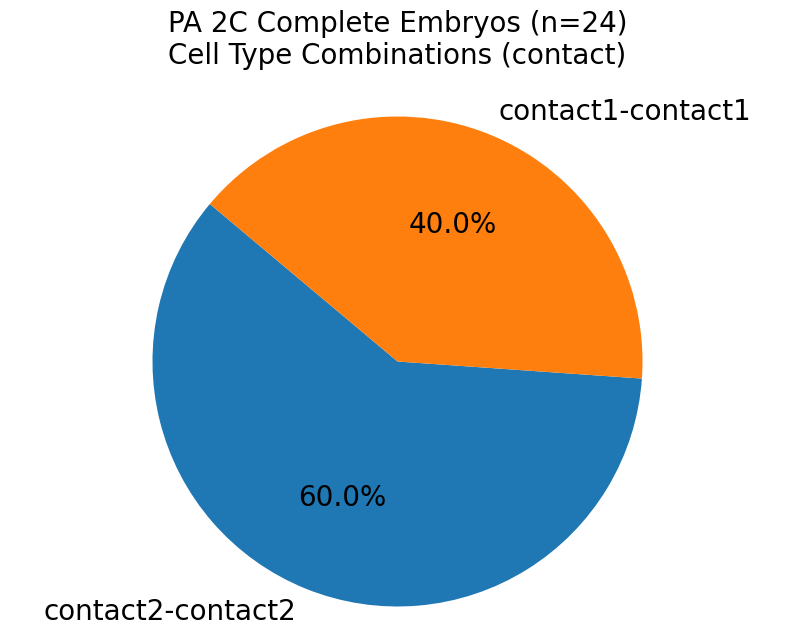

In [57]:
from collections import defaultdict, Counter
import matplotlib.pyplot as plt

input_file_name = "PA_2C_2cluster_category.txt"
output_file_name = "PA_2C_contact_embryo_type_combinations_complete_only.txt"


# =========================
# 1. 读取并解析（已修复）
# =========================
def read_and_parse(input_file_name):

    embryo_data = defaultdict(list)

    with open(input_file_name, 'r') as file:
        for line in file:

            parts = line.strip().split('\t')

            # ❗必须至少两列
            if len(parts) < 2:
                continue

            # 跳过header
            if parts[0] == "ID":
                continue

            # embryo ID（前2段）
            embryo_id_parts = parts[0].split('-')
            if len(embryo_id_parts) < 2:
                continue

            embryo_id = '-'.join(embryo_id_parts[:2])

            # =========================
            # ❗安全解析 cell_type
            # =========================
            ct_parts = parts[1].split('-')

            if len(ct_parts) < 3:
                continue

            cell_type = ct_parts[-1]   # ✔ 永远取最后一段 ps1/ps2

            embryo_data[embryo_id].append(cell_type)

    return embryo_data


# =========================
# 2. 过滤完整胚胎
# =========================
def count_complete_embryos(embryo_data):

    embryo_type_count = Counter()
    filtered_embryos = {}

    for embryo_id, cell_types in embryo_data.items():

        # 必须2个细胞
        if len(cell_types) != 2:
            continue

        # 剔除异常
        if "FailedQC" in cell_types or "Undefined" in cell_types:
            continue

        filtered_embryos[embryo_id] = cell_types

        sorted_types = sorted(cell_types)

        if sorted_types[0] == sorted_types[1]:
            combination = f"{sorted_types[0]}-{sorted_types[0]}"
        else:
            combination = '-'.join(sorted_types)

        embryo_type_count[combination] += 1

    total_embryos = len(filtered_embryos)

    return filtered_embryos, embryo_type_count, total_embryos


# =========================
# 3. 输出
# =========================
def write_results(embryo_data, combination_counts, total_embryos, output_file_name):

    with open(output_file_name, 'w') as f:

        f.write("PA-2C embryo ps combination\n\n")

        for embryo_id, cell_types in embryo_data.items():

            sorted_types = sorted(cell_types)

            if sorted_types[0] == sorted_types[1]:
                comb = f"{sorted_types[0]}-{sorted_types[0]}"
            else:
                comb = '-'.join(sorted_types)

            f.write(f"{embryo_id}\t{comb}\n")

        f.write("\nSummary:\n")

        for k, v in combination_counts.items():
            f.write(f"{k}: {v} ({v/total_embryos*100:.2f}%)\n")


# =========================
# 4. 饼图（红色标 ps1+ps2）
# =========================
def plot_pie_chart(combination_counts, total_embryos):

    labels = list(combination_counts.keys())
    sizes = list(combination_counts.values())

    plt.figure(figsize=(10, 7))

    wedges, texts, autotexts = plt.pie(
        sizes,
        labels=labels,
        autopct='%1.1f%%',
        startangle=140,
        textprops={'fontsize': 20}
    )

    for i, text in enumerate(texts):
        if "ps1" in labels[i] and "ps2" in labels[i]:
            text.set_color("red")
            text.set_fontweight("bold")

    plt.axis('equal')
    plt.title(f"PA 2C Complete Embryos (n=24)\nCell Type Combinations (contact)", fontsize=20,pad=20)
    plt.show()


# =========================
# 5. 主函数
# =========================
def main():

    embryo_data = read_and_parse(input_file_name)

    filtered, counts, total = count_complete_embryos(embryo_data)

    print("complete embryos:", total)

    write_results(filtered, counts, total, output_file_name)

    plot_pie_chart(counts, total)


if __name__ == "__main__":
    main()

complete embryos: 10

[RED EMBRYOS: contain both ps1 and ps2]

4-195
G4-10
G4-18

Total red embryos: 3


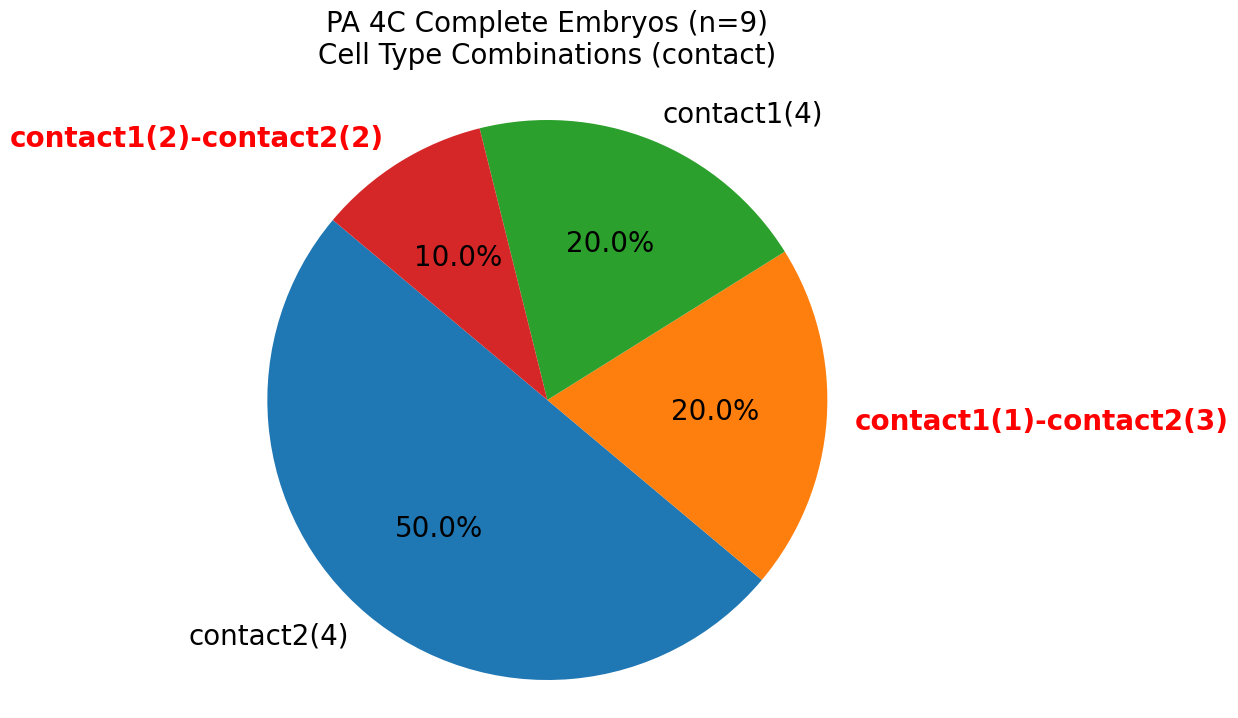

In [60]:
from collections import defaultdict, Counter
import matplotlib.pyplot as plt

input_file_name = "PA_4C_2cluster_category.txt"
output_file_name = "PA_4C_contact_embryo_type_combinations_complete_only.txt"


# =========================
# 1. 读取并解析（安全版）
# =========================
def read_and_parse(input_file_name):

    embryo_data = defaultdict(list)

    with open(input_file_name, 'r') as file:
        for line in file:

            parts = line.strip().split('\t')

            if len(parts) < 2:
                continue

            if parts[0] == "ID":
                continue

            # embryo ID（前2段）
            id_parts = parts[0].split('-')
            if len(id_parts) < 2:
                continue

            embryo_id = '-'.join(id_parts[:2])

            # 安全解析 cell type
            ct_parts = parts[1].split('-')
            if len(ct_parts) < 3:
                continue

            cell_type = ct_parts[-1]

            embryo_data[embryo_id].append(cell_type)

    return embryo_data


# =========================
# 2. 过滤完整4C胚胎
# =========================
def count_complete_embryos(embryo_data):

    embryo_type_count = Counter()
    filtered_embryos = {}

    # ⭐ 新增：组合 -> embryo_id
    combination_to_embryos = defaultdict(list)

    for embryo_id, cell_types in embryo_data.items():

        if len(cell_types) != 4:
            continue

        if "FailedQC" in cell_types or "Undefined" in cell_types:
            continue

        filtered_embryos[embryo_id] = cell_types

        type_count = Counter(cell_types)

        sorted_types = sorted(type_count.items())
        combination = '-'.join([f"{t}({c})" for t, c in sorted_types])

        embryo_type_count[combination] += 1

        # ⭐ 记录映射
        combination_to_embryos[combination].append(embryo_id)

    total_embryos = len(filtered_embryos)

    return filtered_embryos, embryo_type_count, total_embryos, combination_to_embryos


# =========================
# 3. 输出结果
# =========================
def write_results(embryo_data, combination_counts, total_embryos, output_file_name):

    with open(output_file_name, 'w') as f:

        f.write("PA-4C embryo ps composition\n\n")

        for embryo_id, cell_types in embryo_data.items():

            type_count = Counter(cell_types)
            sorted_types = sorted(type_count.items())

            comb = '-'.join([f"{t}({c})" for t, c in sorted_types])

            f.write(f"{embryo_id}\t{comb}\n")

        f.write("\nSummary:\n")

        for k, v in combination_counts.items():
            f.write(f"{k}: {v} ({v/total_embryos*100:.2f}%)\n")


# =========================
# 4. 饼图（ps1+ps2标红）
# =========================
def plot_pie_chart(combination_counts, total_embryos):

    labels = list(combination_counts.keys())
    sizes = list(combination_counts.values())

    plt.figure(figsize=(11, 8))

    wedges, texts, autotexts = plt.pie(
        sizes,
        labels=labels,
        autopct='%1.1f%%',
        startangle=140,
        textprops={'fontsize': 20}
    )

    # 🔴 只要同时含 ps1 + ps2 就标红
    for i, text in enumerate(texts):
        if ("contact1" in labels[i]) and ("contact2" in labels[i]):
            text.set_color("red")
            text.set_fontweight("bold")

    plt.axis('equal')
    plt.title(f"PA 4C Complete Embryos (n=9)\nCell Type Combinations (contact)", fontsize=20,pad=20)
    plt.show()


# =========================
# 5. 主函数
# =========================
def main():

    embryo_data = read_and_parse(input_file_name)

    filtered, counts, total, combo_to_embryos = count_complete_embryos(embryo_data)

    print("complete embryos:", total)

    # =========================
    # 🔴 打印 ps1 + ps2 胚胎
    # =========================
    print("\n[RED EMBRYOS: contain both ps1 and ps2]\n")

    red_list = []

    for combo, eids in combo_to_embryos.items():

        # 只要组合字符串同时包含 ps1 和 ps2
        if ("contact1" in combo) and ("contact2" in combo):
            red_list.extend(eids)

    for eid in red_list:
        print(eid)

    print(f"\nTotal red embryos: {len(red_list)}")

    write_results(filtered, counts, total, output_file_name)

    plot_pie_chart(counts, total)


if __name__ == "__main__":
    main()